Check for gpu

In [ ]:
# Get GPU name
!nvidia-smi -L

GPU 0: Tesla T4 (UUID: GPU-4ddbf9da-6204-e0d7-dd73-7c9d4f5e8054)


In [ ]:
model_name = "yolo11m-seg"

# DATASET
**From Roboflow**
- https://universe.roboflow.com/seg2/dental_project-ee1ur
- https://universe.roboflow.com/dental-z05ko/gum-diseases

**Merged and curated**
- https://universe.roboflow.com/pranta/oralcure_dataset/dataset/2


In [1]:
!pip install --upgrade ultralytics onnxruntime onnxruntime-gpu onnxslim roboflow supervision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 22.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.4/16.4 MB 78.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 283.2/283.2 MB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.2/146.2 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.4/85.4 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 181.5/181.5 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 89.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 39.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 41.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Dataset overview**

*V1*
- image count - 582
  - Train - 429
  - Valid - 77
  - Test  - rest
- Annotaion count per class
  - Train (Caries/Gingivitis/MouthUlcer/Periodontitis) - 300
  - Valid (Caries/Gingivitis/MouthUlcer/Periodontitis) - 46
  - Test  (Caries/Gingivitis/MouthUlcer/Periodontitis) - REST

*V2*
- applied augmentation on V1 train image (430x3) annotation (300x3)
  - Outputs per training example: 3
  - Flip: Horizontal
  - Rotation: Between -5° and +5°
  - Shear: ±3° Horizontal, ±3° Vertical
  - Brightness: Between -10% and +10%
  - Exposure: Between -5% and +5%
  - Blur: Up to 1.5px
  - Noise: Up to 1% of pixels

*V3*
- applied augmentation on V2 train image (1287x3) annotation (900x3)
  - Apply very mild transformations to the V2 train set (1290 images):
  - Rotation: ±2° (minimal adjustment).
  - Brightness: ±5% (subtle change).
  - Noise: Up to 0.5% of pixels (very light).

## Downloading Data

In [ ]:
import os
HOME = os.getcwd()
print(HOME)

!mkdir {HOME}/datasets
%cd {HOME}/datasets

from roboflow import Roboflow
from google.colab import userdata

roboflow_api_key = userdata.get('ROBOFLOW_API_KEY')

rf = Roboflow(api_key=roboflow_api_key)
project = rf.workspace("pranta").project("oralcure_dataset")
version = project.version(2)
dataset = version.download("yolov11")

/content
/content/datasets
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to dental_disease_seg_baln_reaug-2 in yolov11:: 100%|██████████| 1176/1176 [00:00<00:00, 3463.75it/s]


# Feature Extractor model

## Training Object Detection model

In [ ]:
from ultralytics import YOLO

# Load a model
feature_extractor_model = YOLO(f"{model_name}.pt")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


100%|██████████| 43.3M/43.3M [00:00<00:00, 91.9MB/s]


In [ ]:
feature_extractor_model.info()

YOLO11m-seg summary: 253 layers, 22,420,896 parameters, 0 gradients, 123.9 GFLOPs


(253, 22420896, 0, 123.91982079999998)

YOLO11s-seg model has the following specifications:
* Layer Count: 355 layers
* Parameter Count: 10,113,248 parameters
* Gradient Count: 0 gradients (indicating that no parameters are set to require * gradients, which is typical for a feature extraction setup)
* GFLOPs: 35.8 GFLOPs (Giga Floating Point Operations per Second)

In [ ]:
feature_extractor_model.model.yaml

{'nc': 80,
 'scales': {'n': [0.5, 0.25, 1024],
  's': [0.5, 0.5, 1024],
  'm': [0.5, 1.0, 512],
  'l': [1.0, 1.0, 512],
  'x': [1.0, 1.5, 512]},
 'backbone': [[-1, 1, 'Conv', [64, 3, 2]],
  [-1, 1, 'Conv', [128, 3, 2]],
  [-1, 2, 'C3k2', [256, False, 0.25]],
  [-1, 1, 'Conv', [256, 3, 2]],
  [-1, 2, 'C3k2', [512, False, 0.25]],
  [-1, 1, 'Conv', [512, 3, 2]],
  [-1, 2, 'C3k2', [512, True]],
  [-1, 1, 'Conv', [1024, 3, 2]],
  [-1, 2, 'C3k2', [1024, True]],
  [-1, 1, 'SPPF', [1024, 5]],
  [-1, 2, 'C2PSA', [1024]]],
 'head': [[-1, 1, 'nn.Upsample', ['None', 2, 'nearest']],
  [[-1, 6], 1, 'Concat', [1]],
  [-1, 2, 'C3k2', [512, False]],
  [-1, 1, 'nn.Upsample', ['None', 2, 'nearest']],
  [[-1, 4], 1, 'Concat', [1]],
  [-1, 2, 'C3k2', [256, False]],
  [-1, 1, 'Conv', [256, 3, 2]],
  [[-1, 13], 1, 'Concat', [1]],
  [-1, 2, 'C3k2', [512, False]],
  [-1, 1, 'Conv', [512, 3, 2]],
  [[-1, 10], 1, 'Concat', [1]],
  [-1, 2, 'C3k2', [1024, True]],
  [[16, 19, 22], 1, 'Segment', ['nc', 32, 256]]],
 

In [ ]:
for i, layer in enumerate(feature_extractor_model.model.model):
    print(i, layer)

0 Conv(
  (conv): Conv2d(3, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
  (act): SiLU(inplace=True)
)
1 Conv(
  (conv): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn): BatchNorm2d(128, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
  (act): SiLU(inplace=True)
)
2 C3k2(
  (cv1): Conv(
    (conv): Conv2d(128, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(128, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (cv2): Conv(
    (conv): Conv2d(192, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(256, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (m): ModuleList(
    (0): C3k(
      (cv1): Conv(
        (conv): Conv2d(64, 32, kernel_size=(1, 1), stride=(1, 1), bias=Fals

In [ ]:
for i, param in enumerate(feature_extractor_model.model.parameters()):
    print(f"Layer {i}: {'Frozen' if not param.requires_grad else 'Trainable'}")

Layer 0: Frozen
Layer 1: Frozen
Layer 2: Frozen
Layer 3: Frozen
Layer 4: Frozen
Layer 5: Frozen
Layer 6: Frozen
Layer 7: Frozen
Layer 8: Frozen
Layer 9: Frozen
Layer 10: Frozen
Layer 11: Frozen
Layer 12: Frozen
Layer 13: Frozen
Layer 14: Frozen
Layer 15: Frozen
Layer 16: Frozen
Layer 17: Frozen
Layer 18: Frozen
Layer 19: Frozen
Layer 20: Frozen
Layer 21: Frozen
Layer 22: Frozen
Layer 23: Frozen
Layer 24: Frozen
Layer 25: Frozen
Layer 26: Frozen
Layer 27: Frozen
Layer 28: Frozen
Layer 29: Frozen
Layer 30: Frozen
Layer 31: Frozen
Layer 32: Frozen
Layer 33: Frozen
Layer 34: Frozen
Layer 35: Frozen
Layer 36: Frozen
Layer 37: Frozen
Layer 38: Frozen
Layer 39: Frozen
Layer 40: Frozen
Layer 41: Frozen
Layer 42: Frozen
Layer 43: Frozen
Layer 44: Frozen
Layer 45: Frozen
Layer 46: Frozen
Layer 47: Frozen
Layer 48: Frozen
Layer 49: Frozen
Layer 50: Frozen
Layer 51: Frozen
Layer 52: Frozen
Layer 53: Frozen
Layer 54: Frozen
Layer 55: Frozen
Layer 56: Frozen
Layer 57: Frozen
Layer 58: Frozen
Layer 5

Training setting for yolo -> https://docs.ultralytics.com/modes/train/#train-settings

In [ ]:
feature_extraction_results = feature_extractor_model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=50,
    imgsz=640,
    batch=32,
    freeze=11,
    lr0=0.01,
    cos_lr=True,
    patience=20,
    amp=True,
    save=True,
    device=0,
    seed=42
)

Ultralytics 8.3.107 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: task=segment, mode=train, model=yolo11m-seg.pt, data=/content/datasets/dental_disease_seg_baln_reaug-2/data.yaml, epochs=50, time=None, patience=20, batch=32, imgsz=640, save=True, save_period=-1, cache=False, device=0, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=42, deterministic=True, single_cls=False, rect=False, cos_lr=True, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=11, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, save_crop=False, show_labels=True, show_conf=Tr

100%|██████████| 755k/755k [00:00<00:00, 24.1MB/s]


Overriding model.yaml nc=80 with nc=4

                   from  n    params  module                                       arguments                     
  0                  -1  1      1856  ultralytics.nn.modules.conv.Conv             [3, 64, 3, 2]                 
  1                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  2                  -1  1    111872  ultralytics.nn.modules.block.C3k2            [128, 256, 1, True, 0.25]     
  3                  -1  1    590336  ultralytics.nn.modules.conv.Conv             [256, 256, 3, 2]              
  4                  -1  1    444928  ultralytics.nn.modules.block.C3k2            [256, 512, 1, True, 0.25]     
  5                  -1  1   2360320  ultralytics.nn.modules.conv.Conv             [512, 512, 3, 2]              
  6                  -1  1   1380352  ultralytics.nn.modules.block.C3k2            [512, 512, 1, True]           
  7                  -1  1   2360320  ultralytics

100%|██████████| 5.35M/5.35M [00:00<00:00, 95.0MB/s]


AMP: checks passed ✅


train: Scanning /content/datasets/dental_disease_seg_baln_reaug-2/train/labels... 429 images, 0 backgrounds, 0 corrupt: 100%|██████████| 429/429 [00:00<00:00, 1902.81it/s]

... (155 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):   0%|          | 0/2 [00:00<?, ?it/s]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100%|██████████| 2/2 [00:02<00:00,  1.04s/it]


                   all         77        184      0.491      0.462      0.435      0.256      0.501      0.466      0.445      0.224
                Caries         22         46      0.513       0.37      0.406      0.194      0.543      0.387      0.453      0.184
            Gingivitis         12         46       0.37        0.5      0.423      0.238      0.361      0.478      0.405      0.178
           Mouth Ulcer         29         46      0.769      0.522      0.608       0.42      0.774      0.522      0.608      0.392
         Periodontitis         19         46      0.311      0.457      0.303      0.171      0.327      0.478      0.312      0.141
Speed: 0.3ms preprocess, 15.4ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to runs/segment/train


## Save model performance and best weights in drive

In [ ]:
import os
import shutil

source_dir = "/content/datasets/runs"  # Path to the folder you want to save
destination_dir = f"/content/drive/MyDrive/ML/DENTAL_THESIS/{model_name}/feature_extractor"

os.makedirs(destination_dir, exist_ok=True)
shutil.copytree(source_dir, destination_dir, dirs_exist_ok=True)

print(f"All files and folders from {source_dir} have been copied to {destination_dir}.")

All files and folders from /content/datasets/runs have been copied to /content/drive/MyDrive/ML/DENTAL_THESIS/yolo11m-seg/feature_extractor.


## Plot model results

In [ ]:
saved_model_results_path = f"{destination_dir}/segment"

In [ ]:
from IPython.display import Image

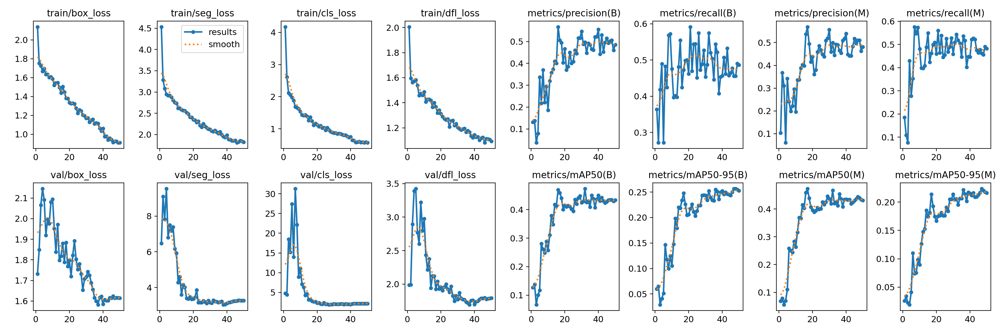

In [ ]:
results_path = f"{saved_model_results_path}/train/results.png"
Image(results_path, width=1000)

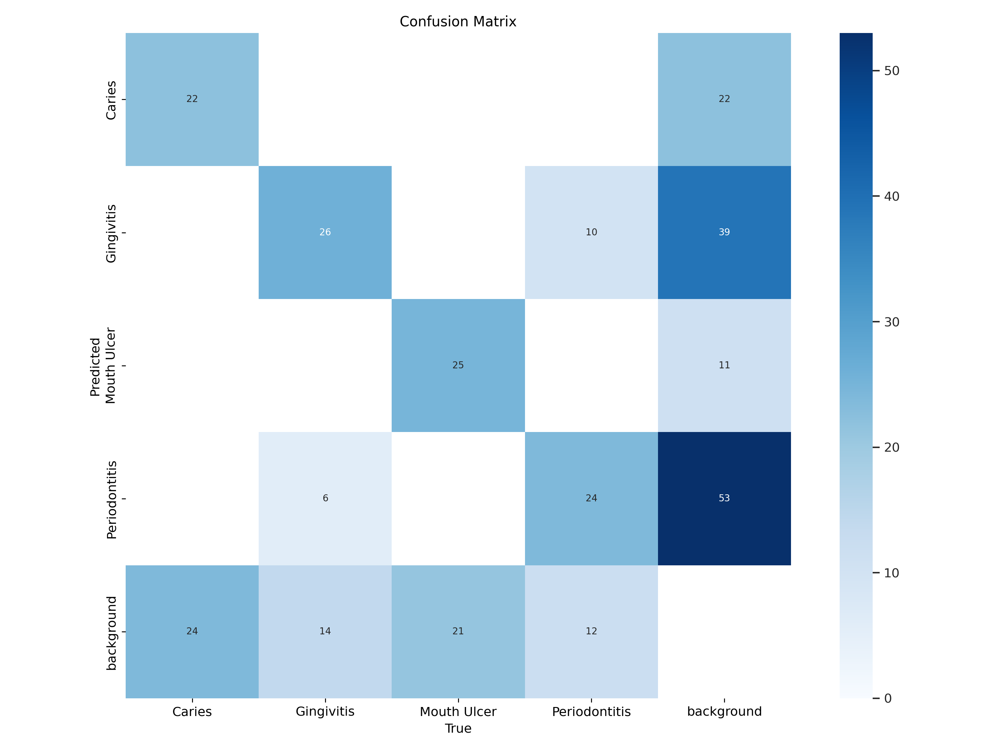

In [ ]:
confusion_matrix_path = f"{saved_model_results_path}/train/confusion_matrix.png"
Image(confusion_matrix_path, width=800)

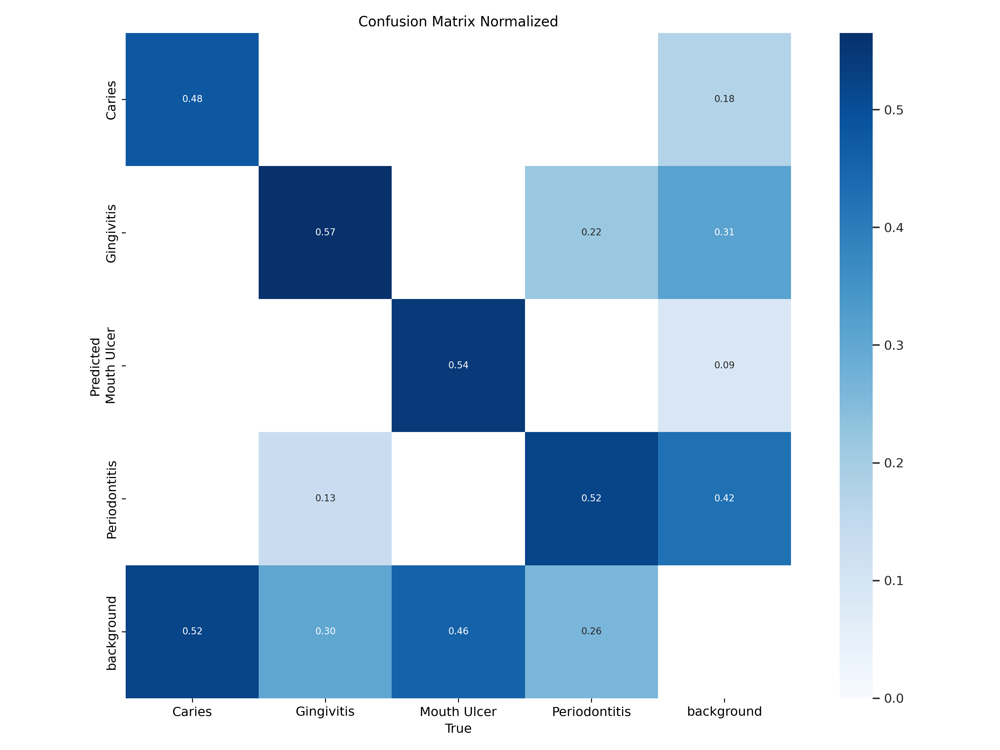

In [ ]:
confusion_matrix_norm_path = f"{saved_model_results_path}/train/confusion_matrix_normalized.png"
Image(confusion_matrix_norm_path, width=800)

### Segmentation results

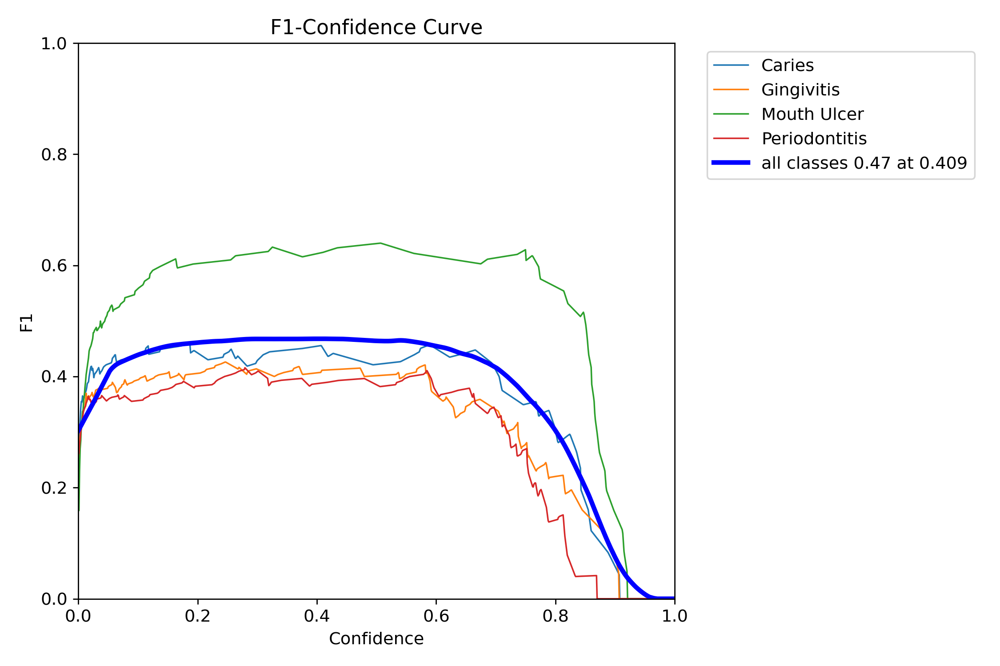

In [ ]:
# mask or segmentation f1 score
f1_curve_path = f"{saved_model_results_path}/train/MaskF1_curve.png"
Image(f1_curve_path, width=800)

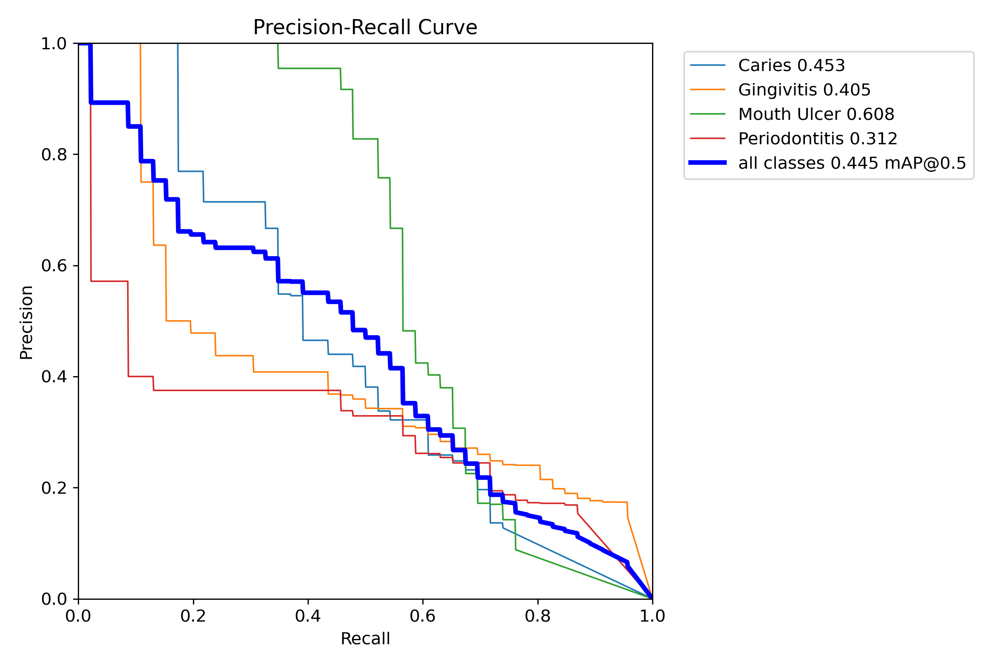

In [ ]:
pr_curve = f"{saved_model_results_path}/train/MaskPR_curve.png"
Image(pr_curve, width=800)

### Detection results

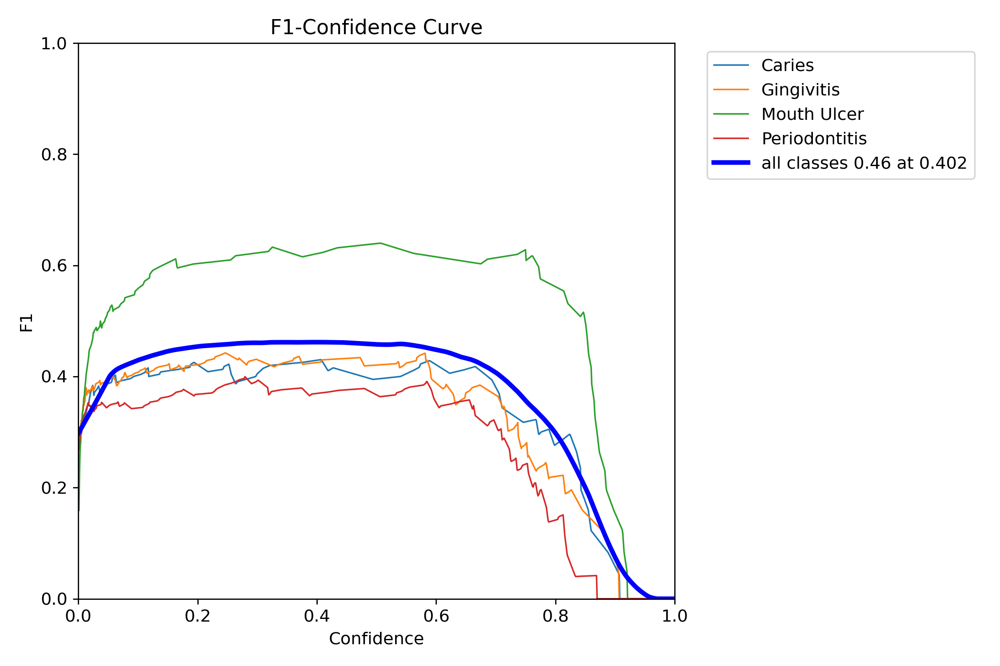

In [ ]:
# bounding box or detection f1 score
f1_curve_box_path = f"{saved_model_results_path}/train/BoxF1_curve.png"
Image(f1_curve_box_path, width=800)

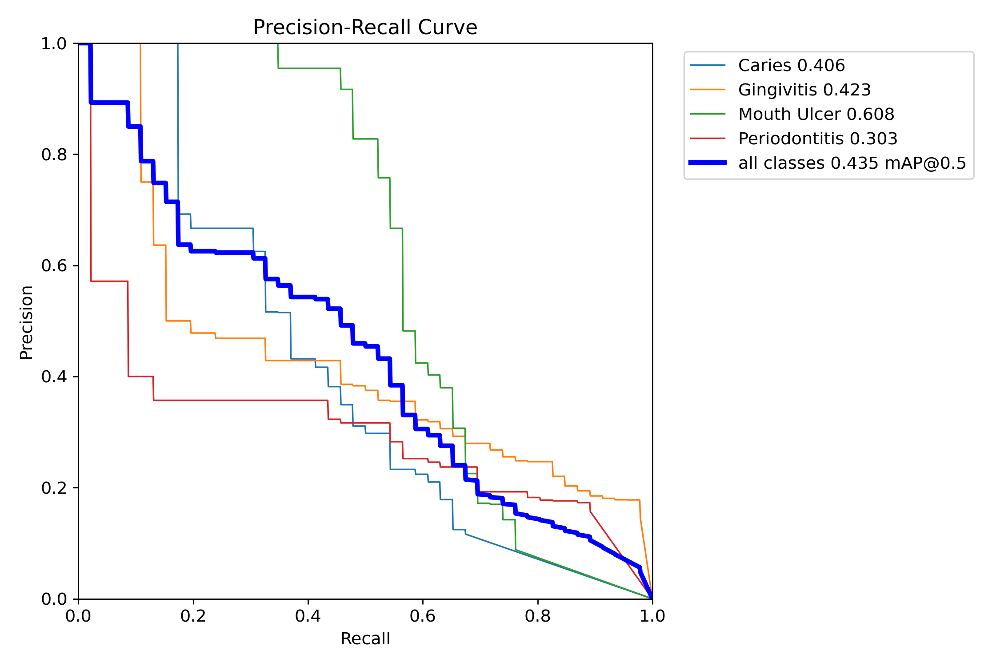

In [ ]:
pr_curve_box_path = f"{saved_model_results_path}/train/BoxPR_curve.png"
Image(pr_curve_box_path, width=800)

### Labels

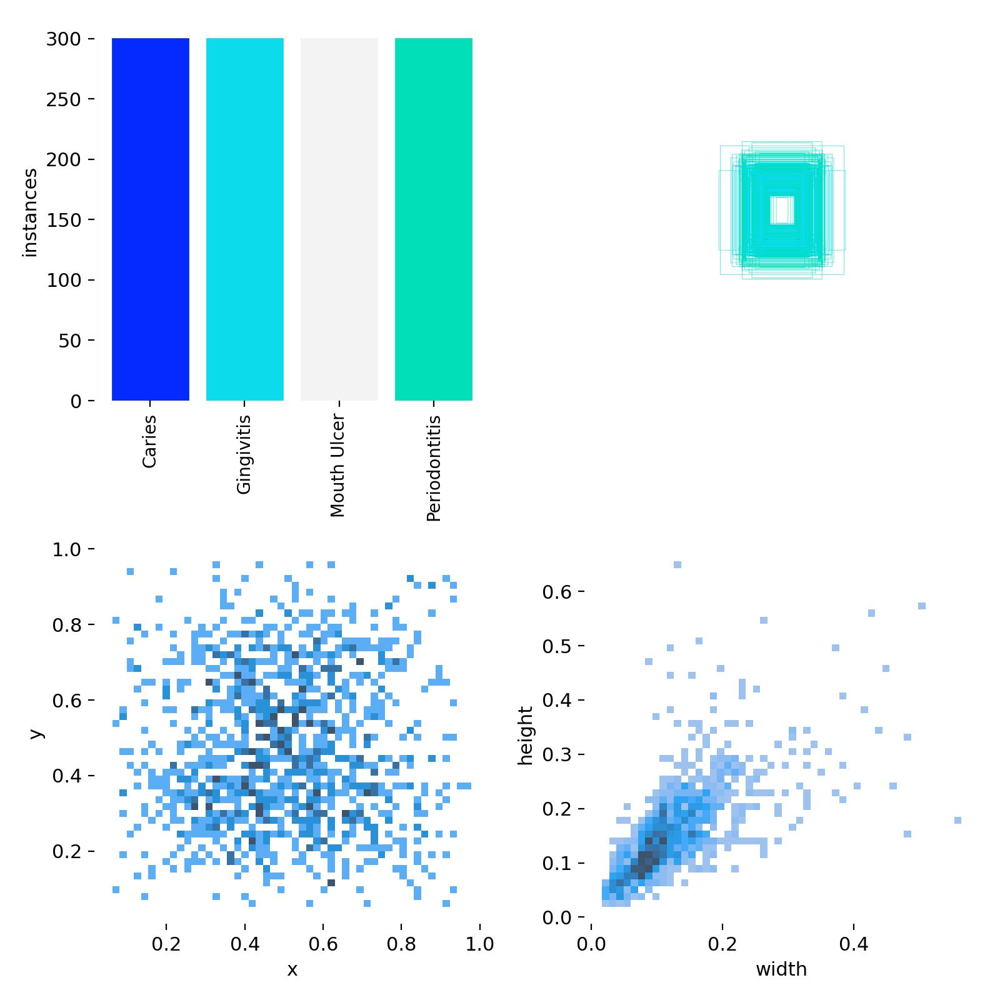

In [ ]:
labels_path = f"{saved_model_results_path}/train/labels.jpg"
Image(labels_path, width=800)

# Validation

In [ ]:
from ultralytics import YOLO

# Load a model
best_weights_path = f"{saved_model_results_path}/train/weights/best.pt"
fe_loaded_best_model = YOLO(best_weights_path)

In [ ]:
fe_loaded_best_model.val()

Ultralytics 8.3.107 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLO11m-seg summary (fused): 138 layers, 22,338,396 parameters, 0 gradients, 123.0 GFLOPs


val: Scanning /content/datasets/dental_disease_seg_baln_reaug-2/valid/labels.cache... 77 images, 0 backgrounds, 0 corrupt: 100%|██████████| 77/77 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):  40%|████      | 2/5 [00:02<00:03,  1.14s/it]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100%|██████████| 5/5 [00:05<00:00,  1.13s/it]


                   all         77        184      0.493      0.458      0.431      0.253      0.492      0.458      0.434       0.22
                Caries         22         46      0.505      0.355      0.406      0.194      0.505      0.355      0.424      0.181
            Gingivitis         12         46      0.378        0.5      0.423      0.238      0.362      0.478      0.404      0.176
           Mouth Ulcer         29         46      0.773      0.522      0.609       0.42      0.773      0.522      0.609       0.39
         Periodontitis         19         46      0.315      0.457      0.286      0.161       0.33      0.478      0.299      0.133
Speed: 5.9ms preprocess, 33.5ms inference, 0.0ms loss, 3.3ms postprocess per image
Results saved to runs/segment/val


ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7be3f7de5450>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0

## Save validation results

In [ ]:
import os
import shutil

source_dir = "/content/datasets/runs/segment/val"  # Path to the folder you want to save
destination_dir = f"/content/drive/MyDrive/ML/DENTAL_THESIS/{model_name}/feature_extractor/segment/val"

os.makedirs(destination_dir, exist_ok=True)
shutil.copytree(source_dir, destination_dir, dirs_exist_ok=True)

print(f"All files and folders from {source_dir} have been copied to {destination_dir}.")

All files and folders from /content/datasets/runs/segment/val have been copied to /content/drive/MyDrive/ML/DENTAL_THESIS/yolo11m-seg/feature_extractor/segment/val.


## Plot a validation image


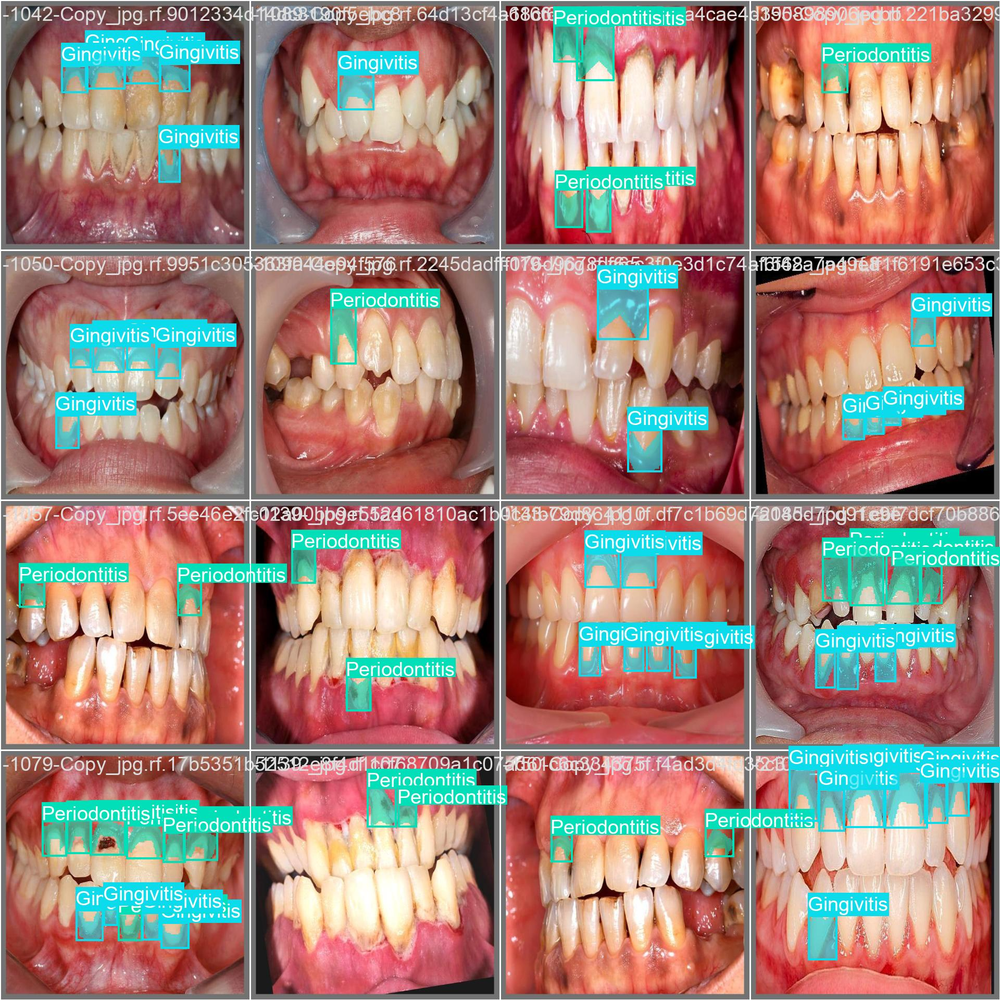

In [ ]:
validation_batch_labels = f"{saved_model_results_path}/val/val_batch0_labels.jpg"
Image(validation_batch_labels, width=1000)

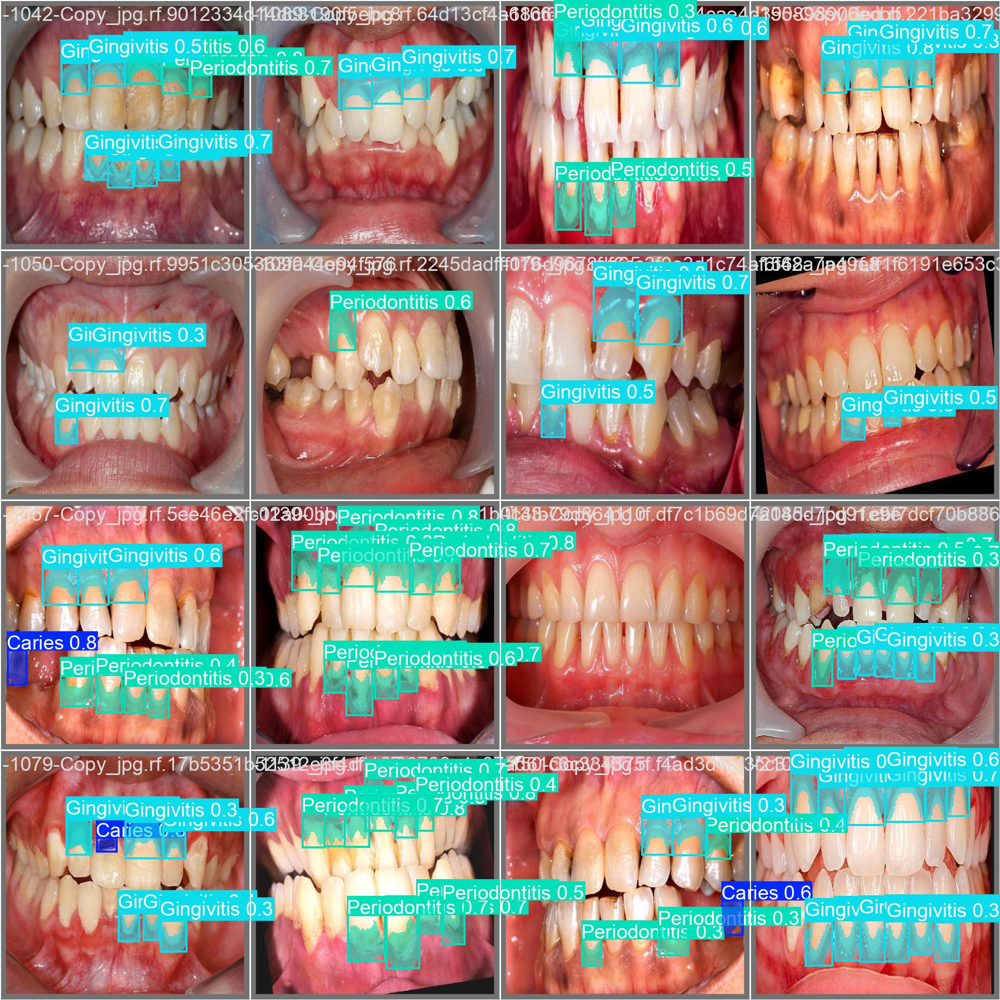

In [ ]:
validation_batch_pred = f"{saved_model_results_path}/val/val_batch0_pred.jpg"
Image(validation_batch_pred, width=1000)

# Model Fine Tuning (IN PROGRESS)

## Dowload augmented data

In [ ]:
import os
HOME = os.getcwd()
print(HOME)

!mkdir {HOME}/datasets
%cd {HOME}/datasets

from roboflow import Roboflow
from google.colab import userdata

roboflow_api_key = userdata.get('ROBOFLOW_API_KEY')

rf = Roboflow(api_key=roboflow_api_key)
project = rf.workspace("pranta").project("oralcure_dataset")
version = project.version(3)
dataset = version.download("yolov11")

/content
/content/datasets
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to dental_disease_seg_baln_reaug-3 in yolov11:: 100%|██████████| 2892/2892 [00:00<00:00, 5993.84it/s]


## Get feature extractor model

In [ ]:
destination_dir = f"/content/drive/MyDrive/ML/DENTAL_THESIS/{model_name}/feature_extractor"
saved_model_results_path = f"{destination_dir}/segment"

In [ ]:
# load the last checkpoint of feature extractor model
from ultralytics import YOLO

# Load a model
best_weights_path = f"{saved_model_results_path}/train/weights/best.pt"
last_weights_path = f"{saved_model_results_path}/train/weights/last.pt"

feature_extractor_last_model = YOLO(last_weights_path)
feature_extractor_last_model.resume = True

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
feature_extractor_last_model.info()

YOLO11m-seg summary: 253 layers, 22,362,300 parameters, 0 gradients, 123.6 GFLOPs


(253, 22362300, 0, 123.59296)

In [ ]:
feature_extractor_last_model.model.yaml

{'nc': 4,
 'scales': {'n': [0.5, 0.25, 1024],
  's': [0.5, 0.5, 1024],
  'm': [0.5, 1.0, 512],
  'l': [1.0, 1.0, 512],
  'x': [1.0, 1.5, 512]},
 'backbone': [[-1, 1, 'Conv', [64, 3, 2]],
  [-1, 1, 'Conv', [128, 3, 2]],
  [-1, 2, 'C3k2', [256, False, 0.25]],
  [-1, 1, 'Conv', [256, 3, 2]],
  [-1, 2, 'C3k2', [512, False, 0.25]],
  [-1, 1, 'Conv', [512, 3, 2]],
  [-1, 2, 'C3k2', [512, True]],
  [-1, 1, 'Conv', [1024, 3, 2]],
  [-1, 2, 'C3k2', [1024, True]],
  [-1, 1, 'SPPF', [1024, 5]],
  [-1, 2, 'C2PSA', [1024]]],
 'head': [[-1, 1, 'nn.Upsample', ['None', 2, 'nearest']],
  [[-1, 6], 1, 'Concat', [1]],
  [-1, 2, 'C3k2', [512, False]],
  [-1, 1, 'nn.Upsample', ['None', 2, 'nearest']],
  [[-1, 4], 1, 'Concat', [1]],
  [-1, 2, 'C3k2', [256, False]],
  [-1, 1, 'Conv', [256, 3, 2]],
  [[-1, 13], 1, 'Concat', [1]],
  [-1, 2, 'C3k2', [512, False]],
  [-1, 1, 'Conv', [512, 3, 2]],
  [[-1, 10], 1, 'Concat', [1]],
  [-1, 2, 'C3k2', [1024, True]],
  [[16, 19, 22], 1, 'Segment', ['nc', 32, 256]]],
 '

## How many layers to freeze for fine tuning (Recommendation):
* Case 1: Dataset is Similar
 - Freeze the first 5 layers:
 - Stops at C3k2 (Index -5).
   Keeps the generic feature extractors frozen while allowing task-specific adaptation for higher-level layers.
* Case 2: Dataset is Different
 - Freeze the first 3 layers:
 - Stops at C3k2 (Index -3).
   Allows more flexibility for the model to learn domain-specific features.
* Case 3: Fully Adapt to New Dataset
 - Freeze the first 2 layers:
 - Stops at Conv (Index -2).
   Only generic features like edges and textures are frozen, with almost the entire backbone trainable.

here we are considering `case2` as we want to train our model to our own domain specific (dental_disease) problem

Staged approach

In [ ]:
partial_fine_tuning_results = feature_extractor_last_model.train(
    data=f"{dataset.location}/data.yaml",
    pretrained=best_weights_path,
    epochs=100,
    imgsz=640,
    batch=32,
    freeze=5,
    lr0=0.001,
    optimizer='AdamW',
    warmup_epochs=0,
    cos_lr=True,
    patience=20,
    amp=True,
    save=True,
    device=0,
    seed=42
)

Ultralytics 8.3.107 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: task=segment, mode=train, model=/content/drive/MyDrive/ML/DENTAL_THESIS/yolo11m-seg/feature_extractor/segment/train/weights/last.pt, data=/content/datasets/dental_disease_seg_baln_reaug-3/data.yaml, epochs=100, time=None, patience=20, batch=32, imgsz=640, save=True, save_period=-1, cache=False, device=0, workers=8, project=None, name=train, exist_ok=False, pretrained=/content/drive/MyDrive/ML/DENTAL_THESIS/yolo11m-seg/feature_extractor/segment/train/weights/best.pt, optimizer=AdamW, verbose=True, seed=42, deterministic=True, single_cls=False, rect=False, cos_lr=True, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=5, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=Fal

100%|██████████| 755k/755k [00:00<00:00, 23.3MB/s]



                   from  n    params  module                                       arguments                     
  0                  -1  1      1856  ultralytics.nn.modules.conv.Conv             [3, 64, 3, 2]                 
  1                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  2                  -1  1    111872  ultralytics.nn.modules.block.C3k2            [128, 256, 1, True, 0.25]     
  3                  -1  1    590336  ultralytics.nn.modules.conv.Conv             [256, 256, 3, 2]              
  4                  -1  1    444928  ultralytics.nn.modules.block.C3k2            [256, 512, 1, True, 0.25]     
  5                  -1  1   2360320  ultralytics.nn.modules.conv.Conv             [512, 512, 3, 2]              
  6                  -1  1   1380352  ultralytics.nn.modules.block.C3k2            [512, 512, 1, True]           
  7                  -1  1   2360320  ultralytics.nn.modules.conv.Conv             [512

100%|██████████| 5.35M/5.35M [00:00<00:00, 104MB/s]


AMP: checks passed ✅


train: Scanning /content/datasets/dental_disease_seg_baln_reaug-3/train/labels... 1287 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1287/1287 [00:00<00:00, 1852.78it/s]


... (124 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):   0%|          | 0/2 [00:00<?, ?it/s]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100%|██████████| 2/2 [00:02<00:00,  1.12s/it]


                   all         77        184      0.574      0.566      0.521      0.277       0.56      0.553        0.5      0.228
                Caries         22         46       0.42      0.522      0.418      0.163      0.401        0.5      0.388       0.15
            Gingivitis         12         46      0.445      0.674       0.47      0.268       0.41       0.63      0.419      0.183
           Mouth Ulcer         29         46      0.883      0.491       0.63      0.395      0.883      0.494      0.627       0.37
         Periodontitis         19         46      0.547      0.578      0.567      0.284      0.546      0.587      0.568      0.209
Speed: 0.2ms preprocess, 17.7ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to runs/segment/train


In [ ]:
import os
import shutil

source_dir = "/content/datasets/runs"  # Path to the folder you want to save
destination_dir = f"/content/drive/MyDrive/ML/DENTAL_THESIS/{model_name}/fine_tuned"

os.makedirs(destination_dir, exist_ok=True)
shutil.copytree(source_dir, destination_dir, dirs_exist_ok=True)

print(f"All files and folders from {source_dir} have been copied to {destination_dir}.")

All files and folders from /content/datasets/runs have been copied to /content/drive/MyDrive/ML/DENTAL_THESIS/yolo11m-seg/fine_tuned.


In [ ]:
saved_model_results_path = f"{destination_dir}/segment"

In [ ]:
from IPython.display import Image

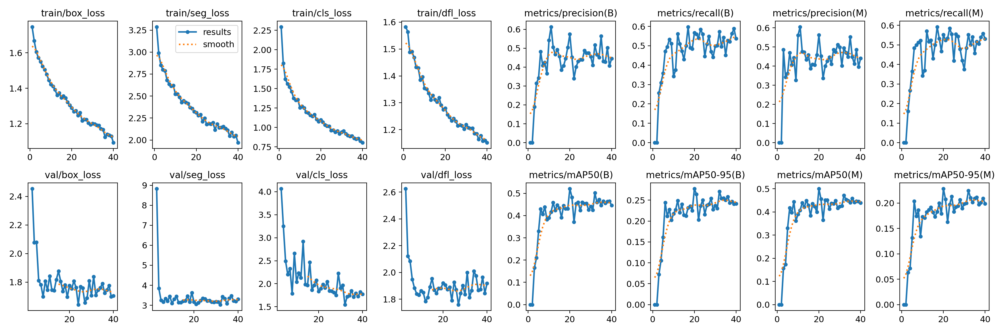

In [ ]:
results_path = f"{saved_model_results_path}/train/results.png"
Image(results_path, width=1000)

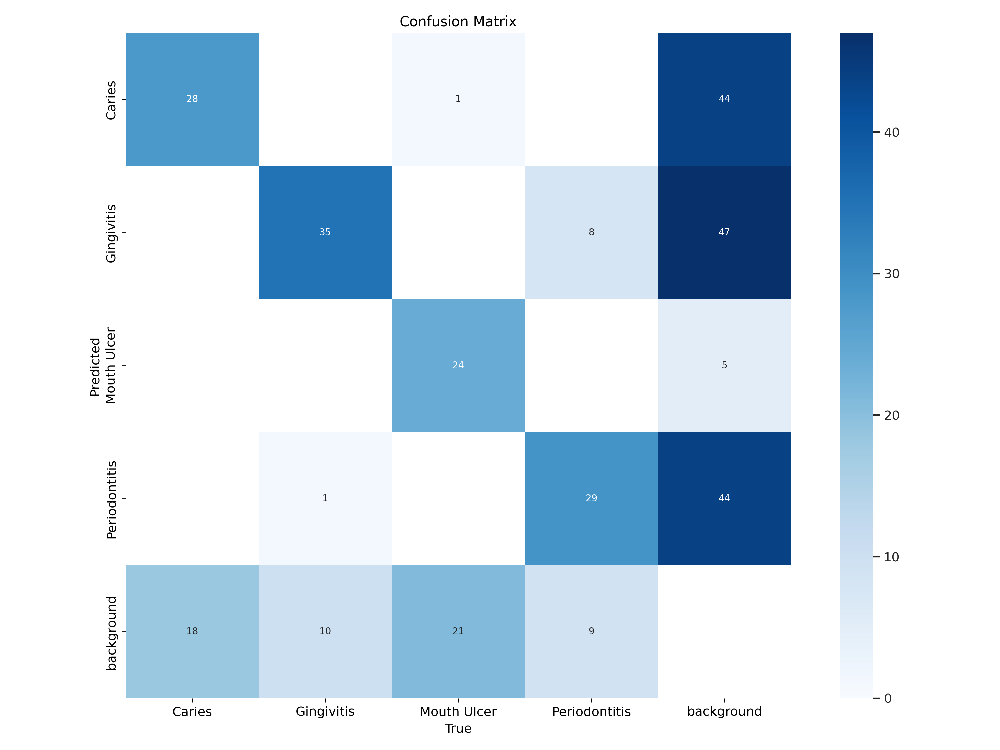

In [ ]:
confusion_matrix_path = f"{saved_model_results_path}/train/confusion_matrix.png"
Image(confusion_matrix_path, width=800)

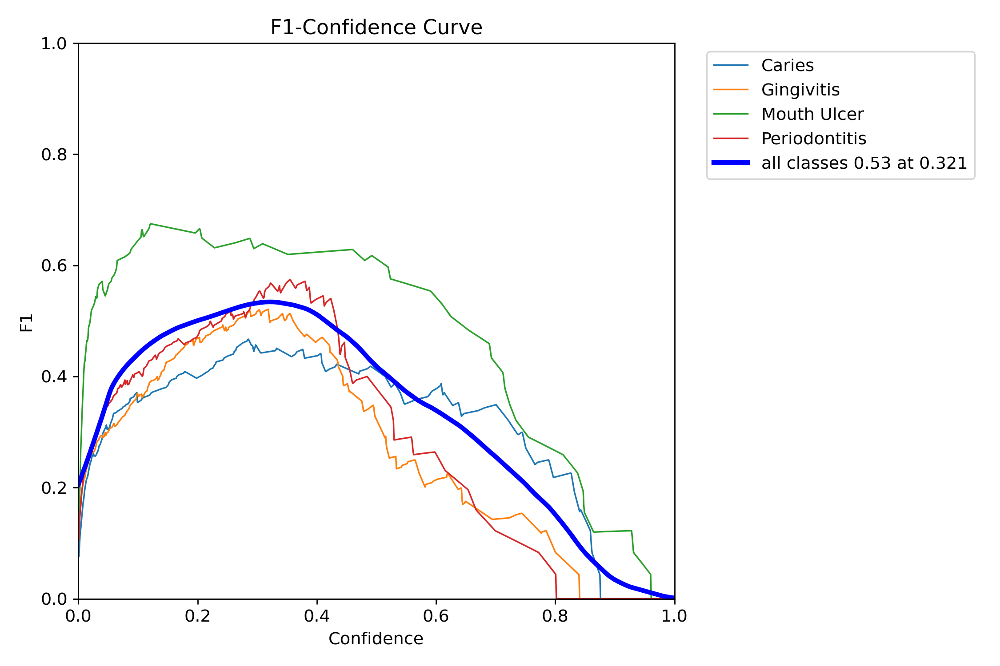

In [ ]:
# mask or segmentation f1 score
f1_curve_path = f"{saved_model_results_path}/train/MaskF1_curve.png"
Image(f1_curve_path, width=800)

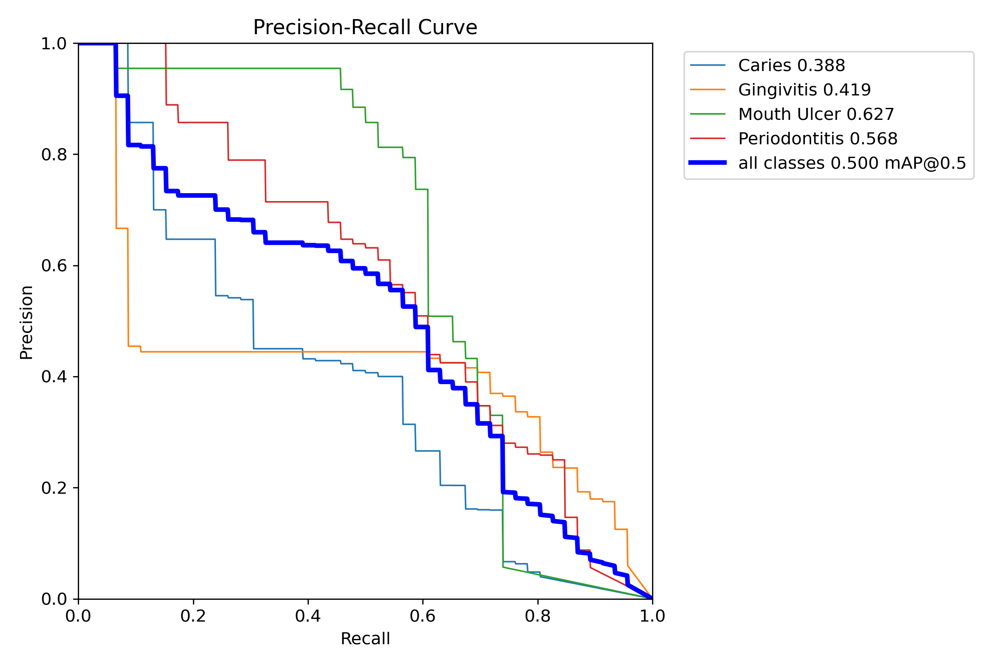

In [ ]:
pr_curve = f"{saved_model_results_path}/train/MaskPR_curve.png"
Image(pr_curve, width=800)

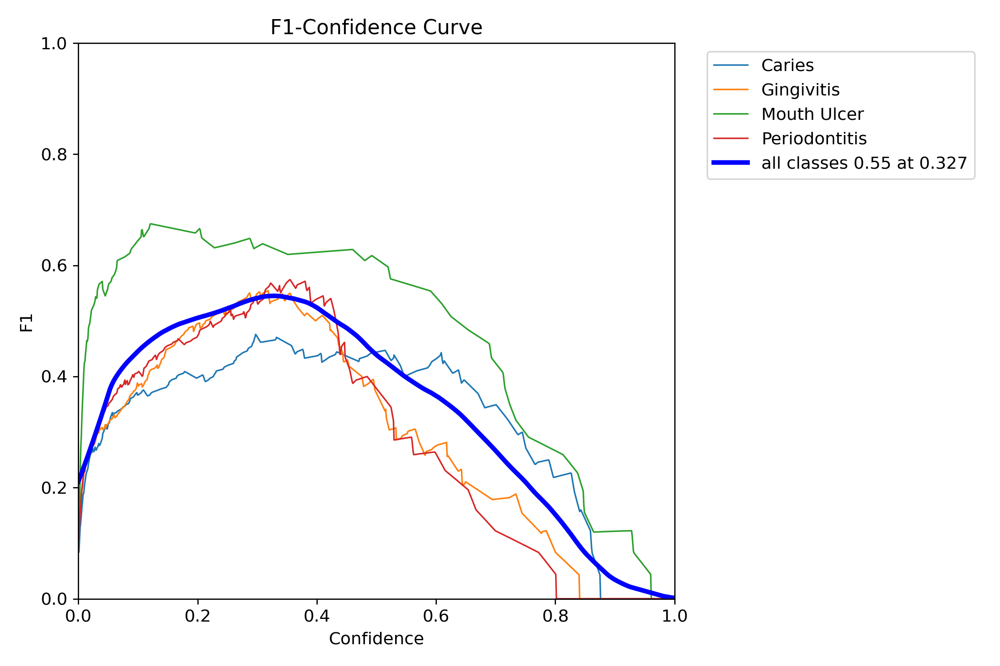

In [ ]:
# bounding box or detection f1 score
f1_curve_box_path = f"{saved_model_results_path}/train/BoxF1_curve.png"
Image(f1_curve_box_path, width=800)

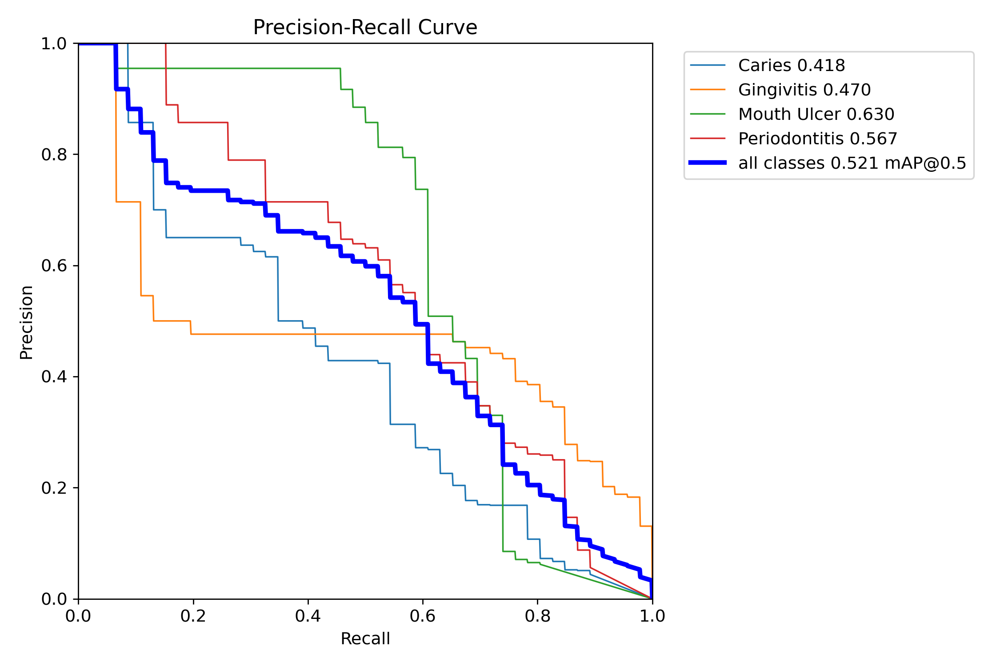

In [ ]:
pr_curve_box_path = f"{saved_model_results_path}/train/BoxPR_curve.png"
Image(pr_curve_box_path, width=800)

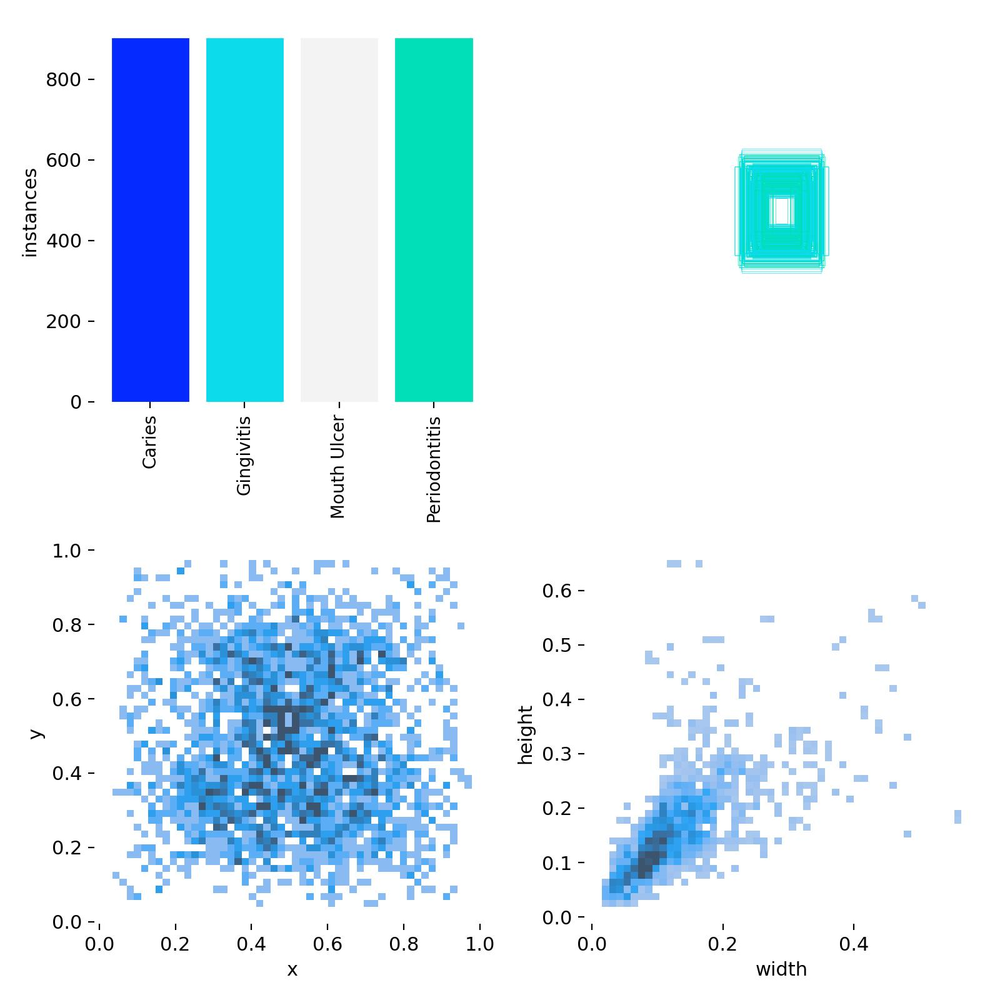

In [ ]:
labels_path = f"{saved_model_results_path}/train/labels.jpg"
Image(labels_path, width=600)

In [ ]:
from ultralytics import YOLO

# Load a model
best_weights_path = f"{saved_model_results_path}/train/weights/best.pt"
ft_loaded_best_model = YOLO(best_weights_path)

In [ ]:
ft_loaded_best_model.val()

Ultralytics 8.3.107 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLO11m-seg summary (fused): 138 layers, 22,338,396 parameters, 0 gradients, 123.0 GFLOPs


val: Scanning /content/datasets/dental_disease_seg_baln_reaug-3/valid/labels.cache... 77 images, 0 backgrounds, 0 corrupt: 100%|██████████| 77/77 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):   0%|          | 0/5 [00:00<?, ?it/s]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):  20%|██        | 1/5 [00:01<00:04,  1.12s/it]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):  40%|████      | 2/5 [00:02<00:04,  1.35s/it]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100%|██████████| 5/5 [00:07<00:00,  1.51s/it]


                   all         77        184      0.574      0.566      0.522      0.279      0.561      0.561      0.501      0.228
                Caries         22         46      0.419      0.522      0.417      0.165        0.4        0.5      0.388      0.152
            Gingivitis         12         46      0.445      0.674      0.472       0.27      0.421      0.663      0.419      0.181
           Mouth Ulcer         29         46      0.883      0.491      0.631      0.397      0.883      0.494      0.627      0.366
         Periodontitis         19         46      0.548      0.579      0.568      0.284      0.542      0.587      0.568      0.213
Speed: 12.8ms preprocess, 40.3ms inference, 0.1ms loss, 4.1ms postprocess per image
Results saved to runs/segment/val


ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d15e8cf8990>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0

## Validate and Plotting validation results

In [ ]:
import os
import shutil

source_dir = "/content/datasets/runs/segment/val"  # Path to the folder you want to save
destination_dir = f"/content/drive/MyDrive/ML/DENTAL_THESIS/{model_name}/fine_tuned/segment/val"

os.makedirs(destination_dir, exist_ok=True)
shutil.copytree(source_dir, destination_dir, dirs_exist_ok=True)

print(f"All files and folders from {source_dir} have been copied to {destination_dir}.")

All files and folders from /content/datasets/runs/segment/val have been copied to /content/drive/MyDrive/ML/DENTAL_THESIS/yolo11m-seg/fine_tuned/segment/val.


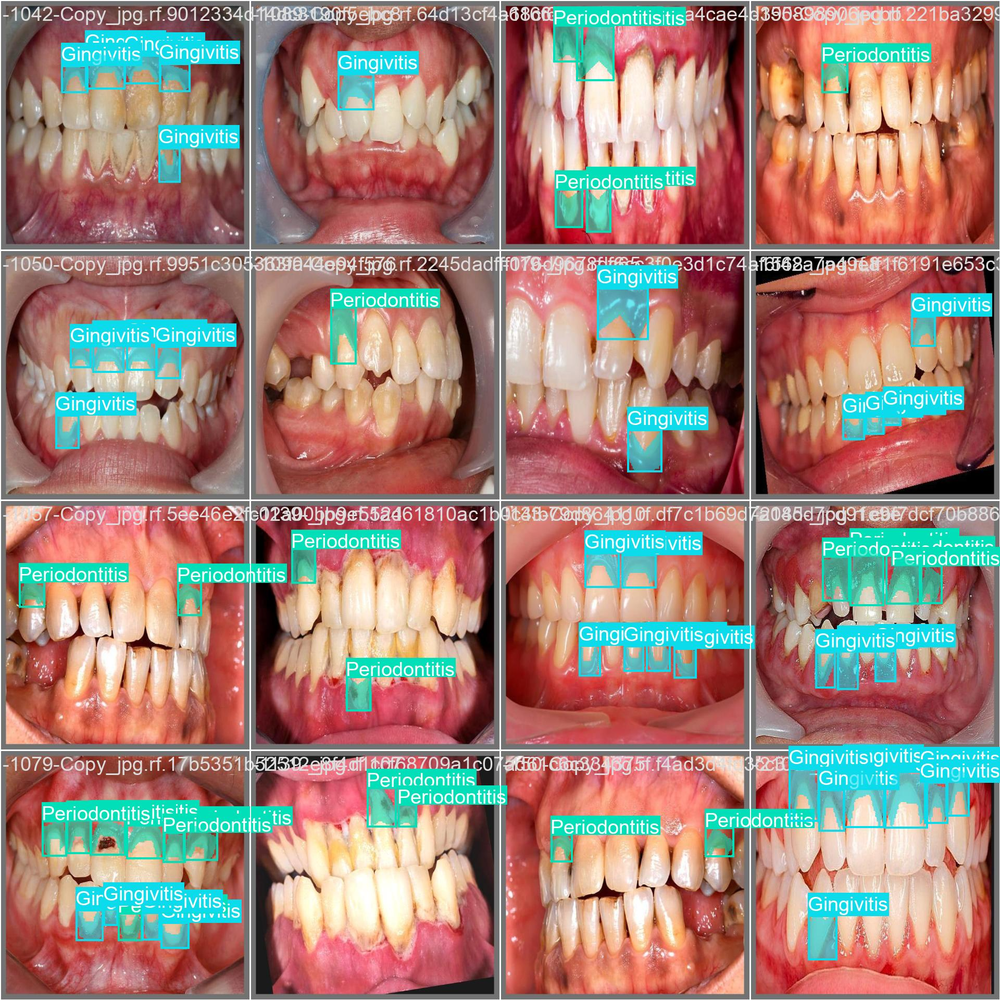

In [ ]:
validation_batch_labels = f"{saved_model_results_path}/val/val_batch0_labels.jpg"
Image(validation_batch_labels, width=1000)

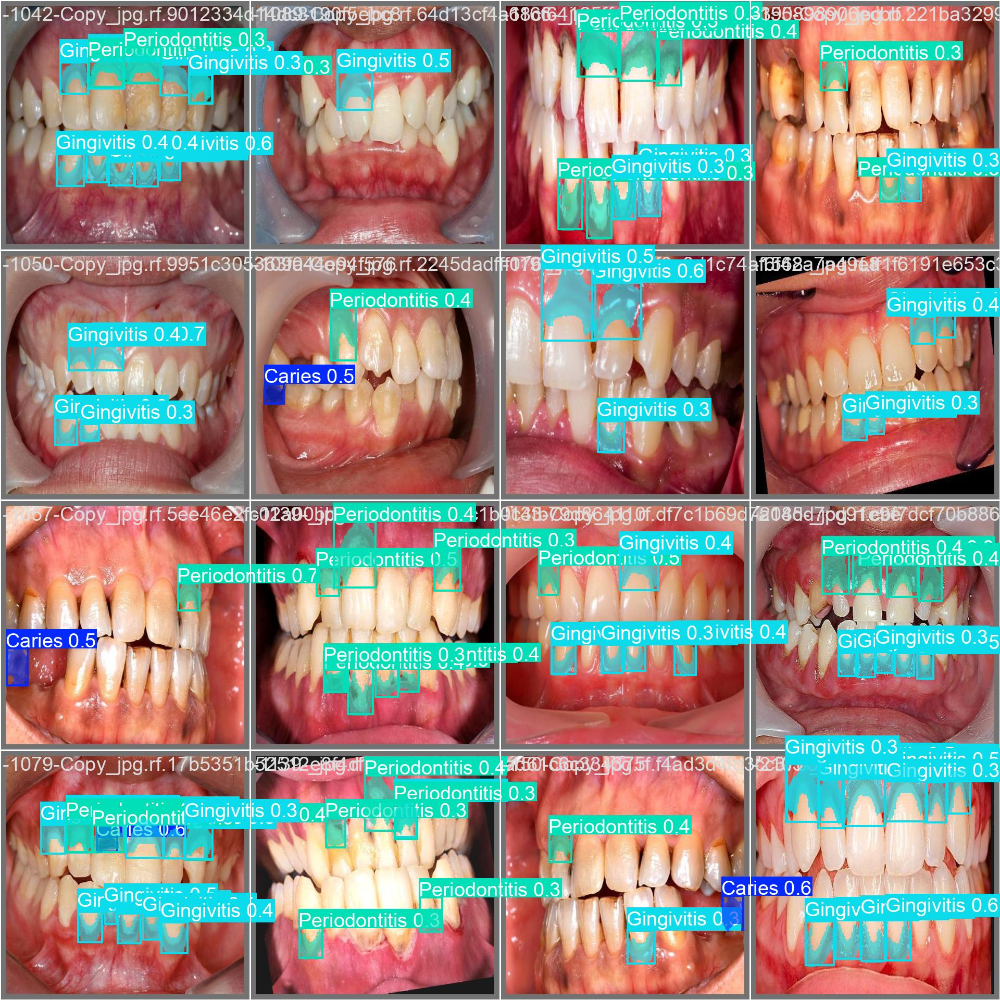

In [ ]:
validation_batch_pred = f"{saved_model_results_path}/val/val_batch0_pred.jpg"
Image(validation_batch_pred, width=1000)

100%|██████████| 16.4k/16.4k [00:00<00:00, 20.3MB/s]

image 1/1 /content/datasets/CAC522B5-A1CC-225C-2AB6559C48211767.jpg: 448x640 3 Gingivitiss, 61.7ms
Speed: 3.1ms preprocess, 61.7ms inference, 15.4ms postprocess per image at shape (1, 3, 448, 640)
Results saved to runs/segment/predict


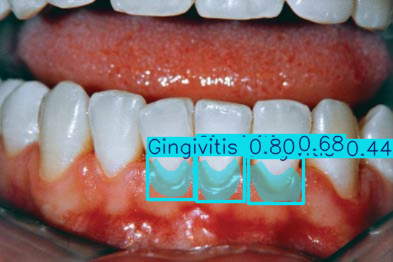

In [ ]:
custom_image_path = "https://cached.imagescaler.hbpl.co.uk/resize/scaleWidth/815/cached.offlinehbpl.hbpl.co.uk/news/PGH/CAC522B5-A1CC-225C-2AB6559C48211767.jpg"
# Perform object detection on an image
results = ft_loaded_best_model(custom_image_path, save=True)
results[0].show()

100%|██████████| 20.1k/20.1k [00:00<00:00, 17.2MB/s]

image 1/1 /content/datasets/dental-caries-web.jpeg: 448x640 3 Cariess, 34.5ms
Speed: 2.3ms preprocess, 34.5ms inference, 2.1ms postprocess per image at shape (1, 3, 448, 640)
Results saved to runs/segment/predict


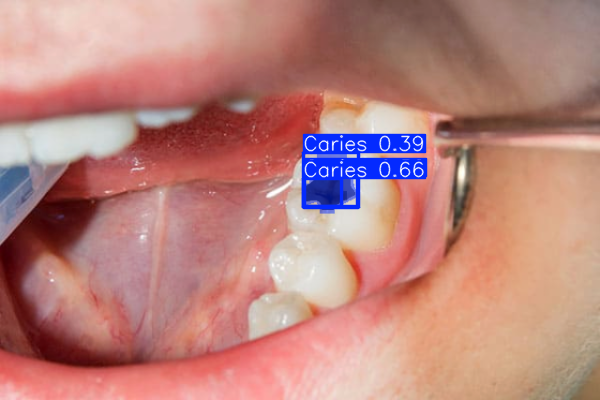

In [ ]:
custom_image_path = "https://www.plagedentistry.com/wp-content/uploads/2020/10/dental-caries-web.jpeg"
# Perform object detection on an image
results = ft_loaded_best_model(custom_image_path, save=True)
results[0].show()

100%|██████████| 25.6k/25.6k [00:00<00:00, 749kB/s]

image 1/1 /content/datasets/caries-dental-en-diente-400x400.jpg: 640x640 3 Cariess, 46.8ms
Speed: 2.8ms preprocess, 46.8ms inference, 2.2ms postprocess per image at shape (1, 3, 640, 640)
Results saved to runs/segment/predict


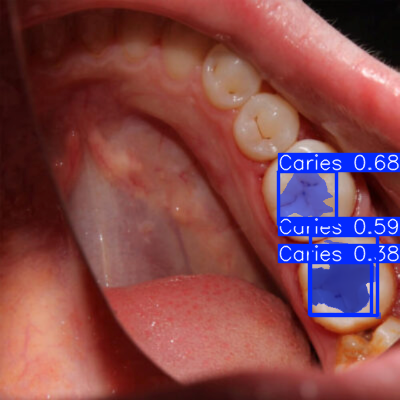

In [ ]:
custom_image_path = "https://famident.hn/wp-content/uploads/2024/10/caries-dental-en-diente-400x400.jpg"
# Perform object detection on an image
results = ft_loaded_best_model(custom_image_path, save=True)
results[0].show()

100%|██████████| 667k/667k [00:01<00:00, 666kB/s]


image 1/1 /content/datasets/que-son-las-caries.jpg: 640x640 6 Cariess, 1 Mouth Ulcer, 50.4ms
Speed: 5.5ms preprocess, 50.4ms inference, 3.1ms postprocess per image at shape (1, 3, 640, 640)
Results saved to runs/segment/predict


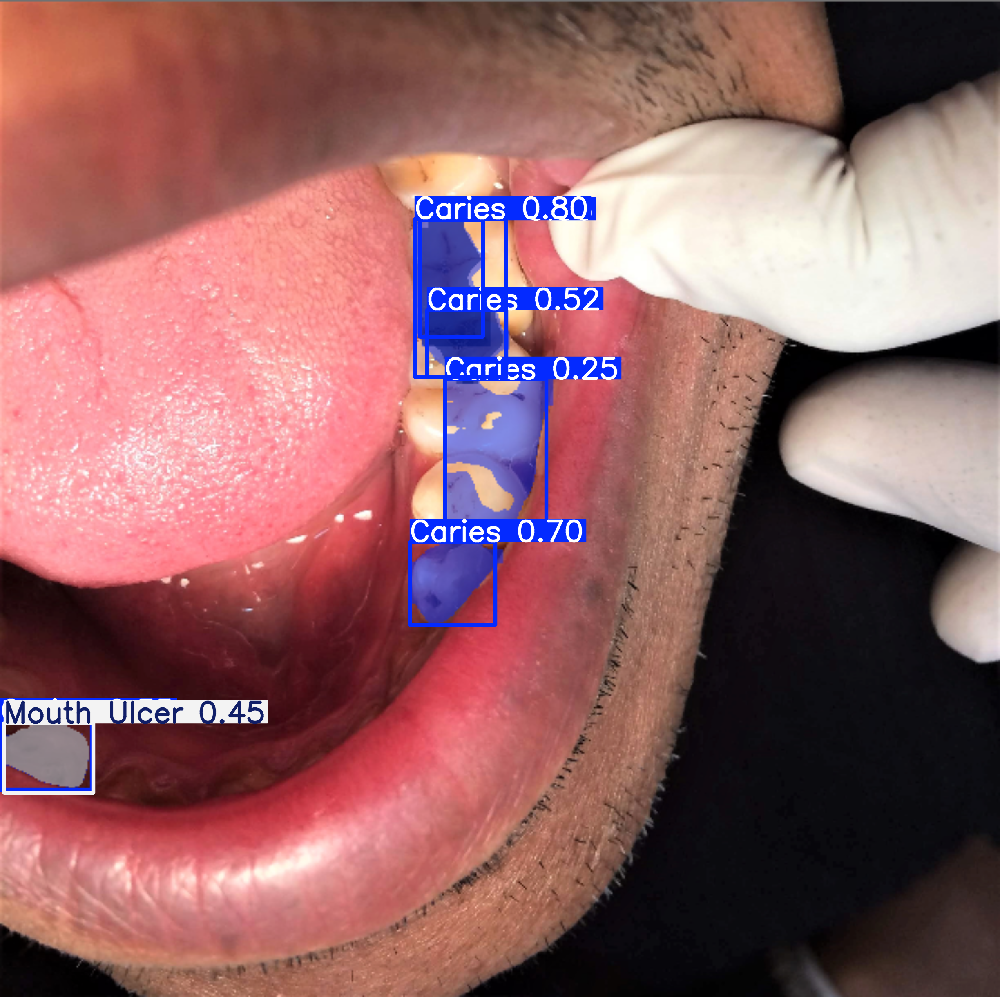

In [ ]:
custom_image_path = "https://www.smysecret.com/blog/wp-content/uploads/2022/09/que-son-las-caries.jpg"
# Perform object detection on an image
results = ft_loaded_best_model(custom_image_path, save=True)
results[0].show()

100%|██████████| 68.6k/68.6k [00:00<00:00, 425kB/s]


image 1/1 /content/datasets/figure-2-2.jpg: 448x640 9 Cariess, 40.6ms
Speed: 2.3ms preprocess, 40.6ms inference, 2.4ms postprocess per image at shape (1, 3, 448, 640)
Results saved to runs/segment/predict


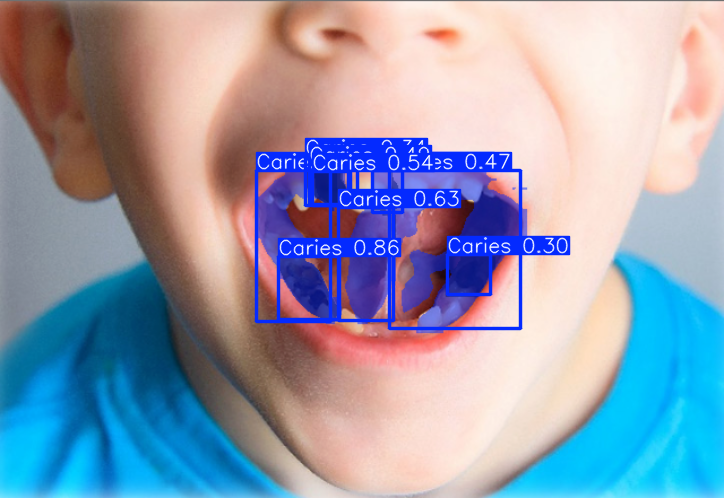

In [ ]:
custom_image_path = "https://dmhuk8np1ucwy.cloudfront.net/up/2023/09/figure-2-2.jpg"
# Perform object detection on an image
results = ft_loaded_best_model(custom_image_path, save=True)
results[0].show()

100%|██████████| 49.3k/49.3k [00:00<00:00, 8.39MB/s]

image 1/1 /content/datasets/Gingivitis-body2-1024x575.jpg: 384x640 5 Gingivitiss, 56.1ms
Speed: 2.3ms preprocess, 56.1ms inference, 2.4ms postprocess per image at shape (1, 3, 384, 640)
Results saved to runs/segment/predict


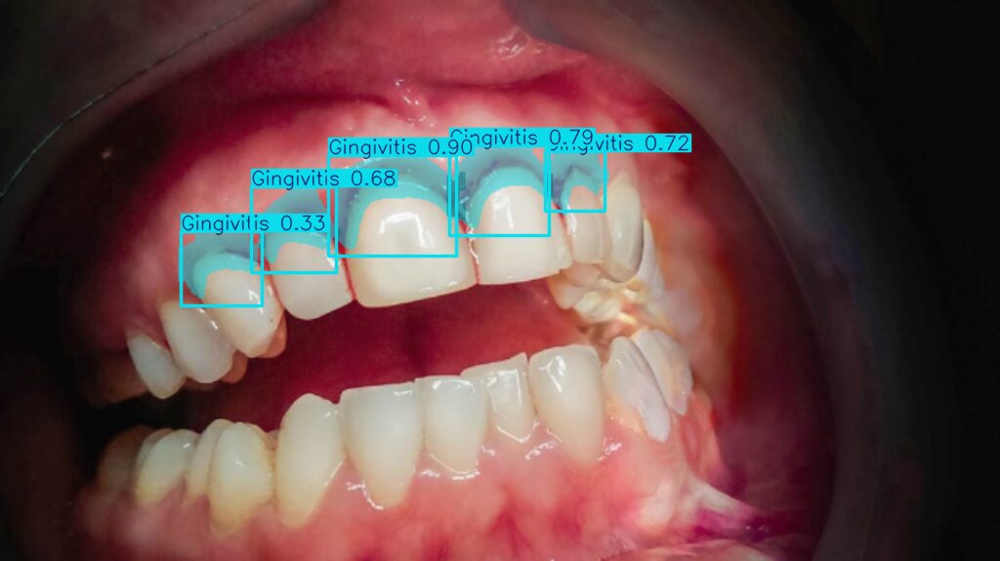

In [ ]:
custom_image_path = "https://post.medicalnewstoday.com/wp-content/uploads/sites/3/2022/01/Gingivitis-body2-1024x575.jpg"
# Perform object detection on an image
results = ft_loaded_best_model(custom_image_path, save=True)
results[0].show()

100%|██████████| 103k/103k [00:00<00:00, 1.73MB/s]

image 1/1 /content/datasets/What-Causes-Mouth-Ulcers-And-How-Can-I-Prevent-Them_-1200x900.jpg: 480x640 1 Mouth Ulcer, 56.9ms
Speed: 3.8ms preprocess, 56.9ms inference, 2.2ms postprocess per image at shape (1, 3, 480, 640)
Results saved to runs/segment/predict


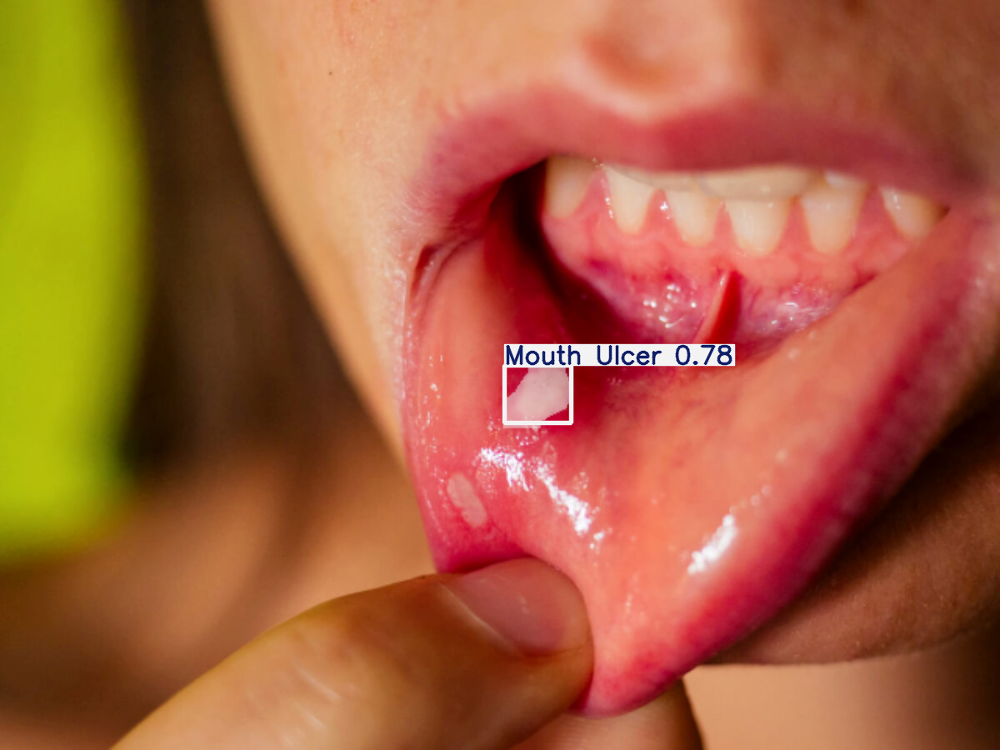

In [ ]:
custom_image_path = "https://www.sintondental.com/wp-content/uploads/2024/01/What-Causes-Mouth-Ulcers-And-How-Can-I-Prevent-Them_-1200x900.jpg"
# Perform object detection on an image
results = ft_loaded_best_model(custom_image_path, save=True)
results[0].show()

100%|██████████| 48.2k/48.2k [00:00<00:00, 1.92MB/s]

image 1/1 /content/datasets/Gingivitis-vs-Periodontitis.webp: 448x640 4 Gingivitiss, 7 Periodontitiss, 39.2ms
Speed: 2.2ms preprocess, 39.2ms inference, 2.3ms postprocess per image at shape (1, 3, 448, 640)
Results saved to runs/segment/predict


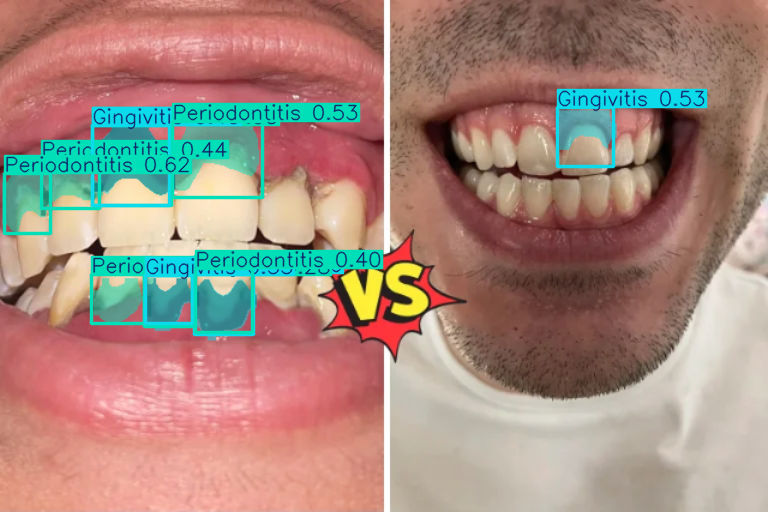

In [ ]:
custom_image_path = "https://www.orisdentalcenter.ae/blog/wp-content/uploads/2024/11/Gingivitis-vs-Periodontitis.webp"
# Perform object detection on an image
results = ft_loaded_best_model(custom_image_path, save=True)
results[0].show()

100%|██████████| 258k/258k [00:00<00:00, 7.46MB/s]

image 1/1 /content/datasets/8318-Digest-Basics-PerioFig1.jpg: 384x640 8 Periodontitiss, 33.6ms
Speed: 2.2ms preprocess, 33.6ms inference, 2.2ms postprocess per image at shape (1, 3, 384, 640)
Results saved to runs/segment/predict


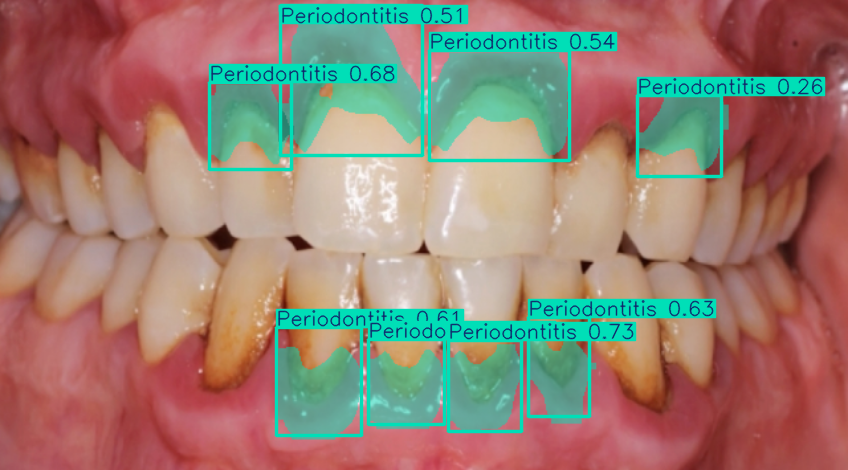

In [ ]:
custom_image_path = "https://assets.speareducation.com/digest/2024/02/back-to-basics-1-diagnosing-periodontitis-2018-classification/8318-Digest-Basics-PerioFig1.jpg"
# Perform object detection on an image
results = ft_loaded_best_model(custom_image_path, save=True)
results[0].show()

# Scaling up fine tuning all layers

## Download data

In [5]:
import os
HOME = os.getcwd()
print(HOME)

!mkdir {HOME}/datasets
%cd {HOME}/datasets

from roboflow import Roboflow
from google.colab import userdata

roboflow_api_key = userdata.get('ROBOFLOW_API_KEY')

rf = Roboflow(api_key=roboflow_api_key)
project = rf.workspace("pranta").project("oralcure_dataset")
version = project.version(4)
dataset = version.download("yolov11")

/content
/content/datasets
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to OralCure_Dataset-4 in yolov11:: 100%|██████████| 8040/8040 [00:01<00:00, 5849.81it/s]


## Get fine tuned model

In [ ]:
destination_dir = f"/content/drive/MyDrive/ML/DENTAL_THESIS/{model_name}/fine_tuned"
saved_model_results_path = f"{destination_dir}/segment"

In [ ]:
# load the last checkpoint of partial fine tuned model
from ultralytics import YOLO

# Load a model
best_weights_path = f"{saved_model_results_path}/train/weights/best.pt"
last_weights_path = f"{saved_model_results_path}/train/weights/last.pt"

fine_tuned_last_model = YOLO(last_weights_path)
fine_tuned_last_model.resume = True

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
scaled_up_results = fine_tuned_last_model.train(
    data=f"{dataset.location}/data.yaml",
    pretrained=best_weights_path,
    epochs=200,
    imgsz=640,
    batch=16,
    freeze=None,
    lr0=0.005,
    optimizer='AdamW',
    warmup_epochs=0,
    cos_lr=True,
    patience=20,
    amp=True,
    save=True,
    plots=True,
    device=0,
    seed=42
)

Ultralytics 8.3.121 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: task=segment, mode=train, model=/content/drive/MyDrive/ML/DENTAL_THESIS/yolo11m-seg/fine_tuned/segment/train/weights/last.pt, data=/content/datasets/dental_disease_seg_baln_reaug-4/data.yaml, epochs=200, time=None, patience=20, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=0, workers=8, project=None, name=train, exist_ok=False, pretrained=/content/drive/MyDrive/ML/DENTAL_THESIS/yolo11m-seg/fine_tuned/segment/train/weights/best.pt, optimizer=AdamW, verbose=True, seed=42, deterministic=True, single_cls=False, rect=False, cos_lr=True, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnosti

100%|██████████| 755k/755k [00:00<00:00, 23.4MB/s]


                   from  n    params  module                                       arguments                     
  0                  -1  1      1856  ultralytics.nn.modules.conv.Conv             [3, 64, 3, 2]                 
  1                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  2                  -1  1    111872  ultralytics.nn.modules.block.C3k2            [128, 256, 1, True, 0.25]     
  3                  -1  1    590336  ultralytics.nn.modules.conv.Conv             [256, 256, 3, 2]              
  4                  -1  1    444928  ultralytics.nn.modules.block.C3k2            [256, 512, 1, True, 0.25]     
  5                  -1  1   2360320  ultralytics.nn.modules.conv.Conv             [512, 512, 3, 2]              
  6                  -1  1   1380352  ultralytics.nn.modules.block.C3k2            [512, 512, 1, True]           
  7                  -1  1   2360320  ultralytics.nn.modules.conv.Conv             [512

 13                  -1  1   1642496  ultralytics.nn.modules.block.C3k2            [1024, 512, 1, True]          
 14                  -1  1         0  torch.nn.modules.upsampling.Upsample         [None, 2, 'nearest']          
 15             [-1, 4]  1         0  ultralytics.nn.modules.conv.Concat           [1]                           
 16                  -1  1    542720  ultralytics.nn.modules.block.C3k2            [1024, 256, 1, True]          
 17                  -1  1    590336  ultralytics.nn.modules.conv.Conv             [256, 256, 3, 2]              
 18            [-1, 13]  1         0  ultralytics.nn.modules.conv.Concat           [1]                           
 19                  -1  1   1511424  ultralytics.nn.modules.block.C3k2            [768, 512, 1, True]           
 20                  -1  1   2360320  ultralytics.nn.modules.conv.Conv             [512, 512, 3, 2]              
 21            [-1, 10]  1         0  ultralytics.nn.modules.conv.Concat           [1]  

100%|██████████| 5.35M/5.35M [00:00<00:00, 96.1MB/s]


AMP: checks passed ✅
train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1466.7±612.5 MB/s, size: 63.9 KB)


... (135 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):  67%|██████▋   | 2/3 [00:02<00:01,  1.14s/it]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100%|██████████| 3/3 [00:03<00:00,  1.16s/it]


                   all         77        184      0.545      0.451      0.472      0.246      0.541      0.429      0.453      0.187
                Caries         22         46      0.704      0.217      0.417      0.151      0.674      0.196      0.369      0.122
            Gingivitis         12         46      0.411      0.435       0.47      0.275      0.413      0.413      0.439      0.165
           Mouth Ulcer         29         46      0.762      0.587      0.605      0.352      0.781      0.587      0.596      0.323
         Periodontitis         19         46      0.304      0.565      0.397      0.205      0.298      0.522      0.406      0.137
Speed: 0.3ms preprocess, 16.3ms inference, 0.0ms loss, 2.7ms postprocess per image
Results saved to runs/segment/train


In [ ]:
import os
import shutil

source_dir = "/content/datasets/runs"  # Path to the folder you want to save
destination_dir = f"/content/drive/MyDrive/ML/DENTAL_THESIS/{model_name}/scaled_up"

os.makedirs(destination_dir, exist_ok=True)
shutil.copytree(source_dir, destination_dir, dirs_exist_ok=True)

print(f"All files and folders from {source_dir} have been copied to {destination_dir}.")

All files and folders from /content/datasets/runs have been copied to /content/drive/MyDrive/ML/DENTAL_THESIS/yolo11m-seg/scaled_up.


In [ ]:
saved_model_results_path = f"{destination_dir}/segment"

In [ ]:
from IPython.display import Image

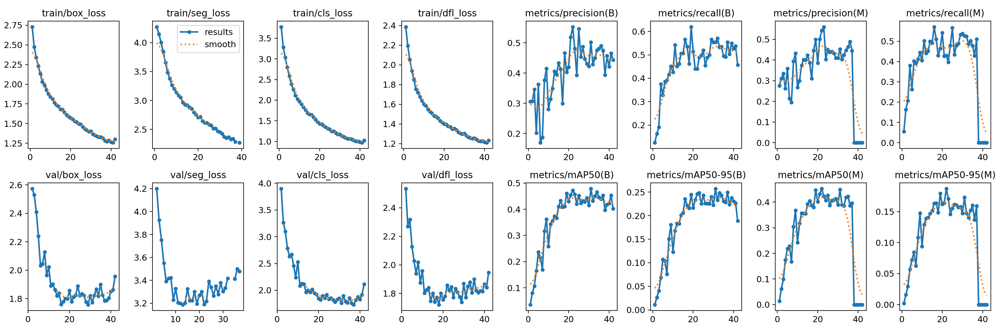

In [ ]:
results_path = f"{saved_model_results_path}/train/results.png"
Image(results_path, width=1000)

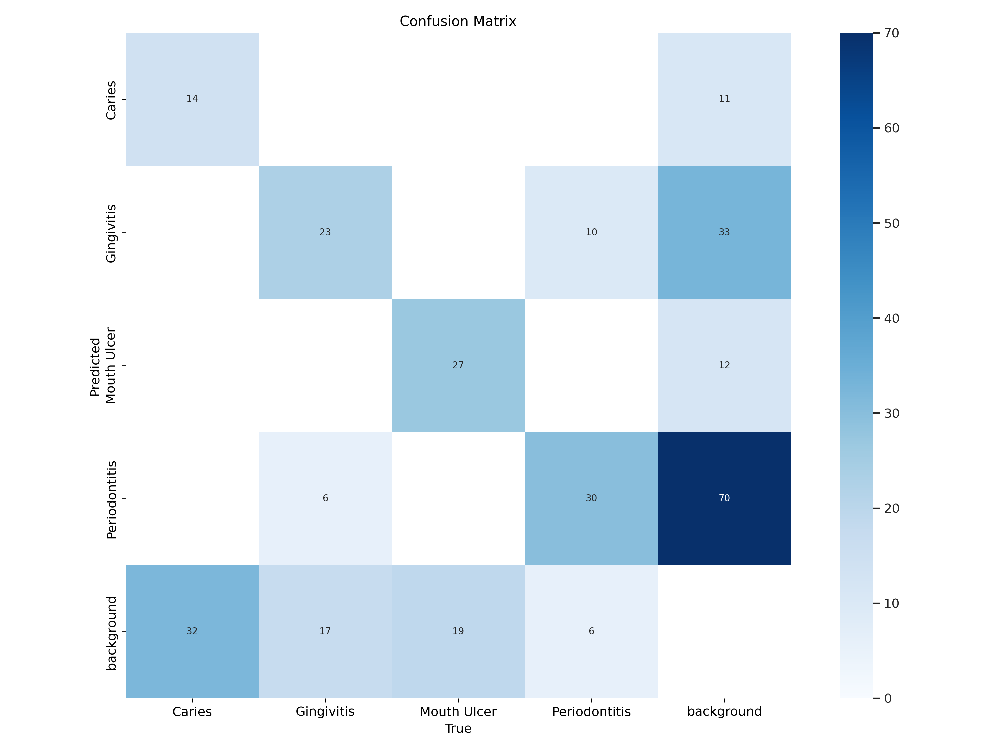

In [ ]:
confusion_matrix_path = f"{saved_model_results_path}/train/confusion_matrix.png"
Image(confusion_matrix_path, width=800)

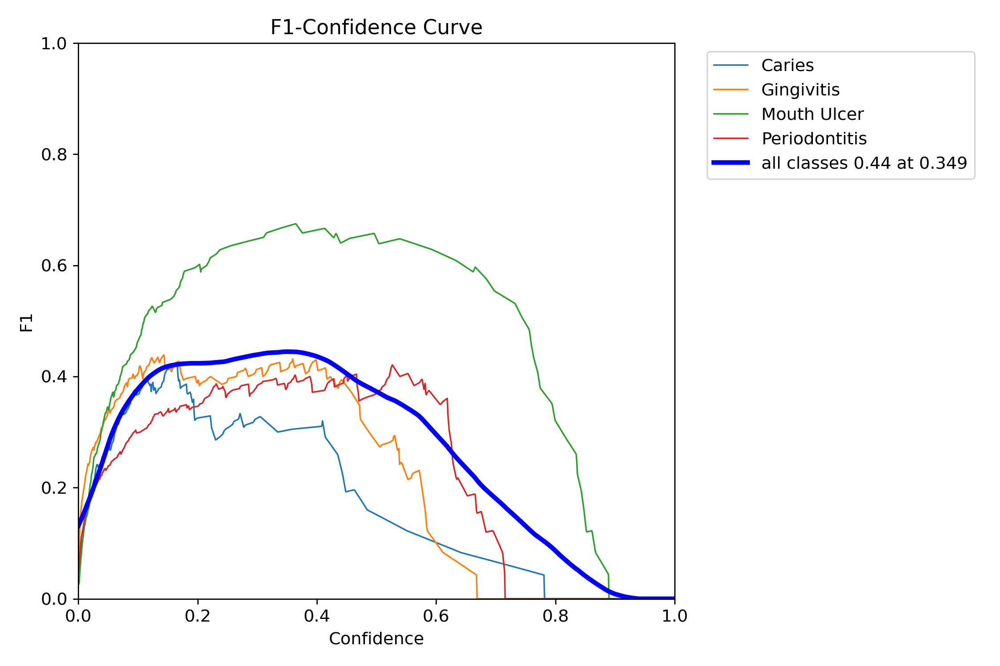

In [ ]:
# mask or segmentation f1 score
f1_curve_path = f"{saved_model_results_path}/train/MaskF1_curve.png"
Image(f1_curve_path, width=800)

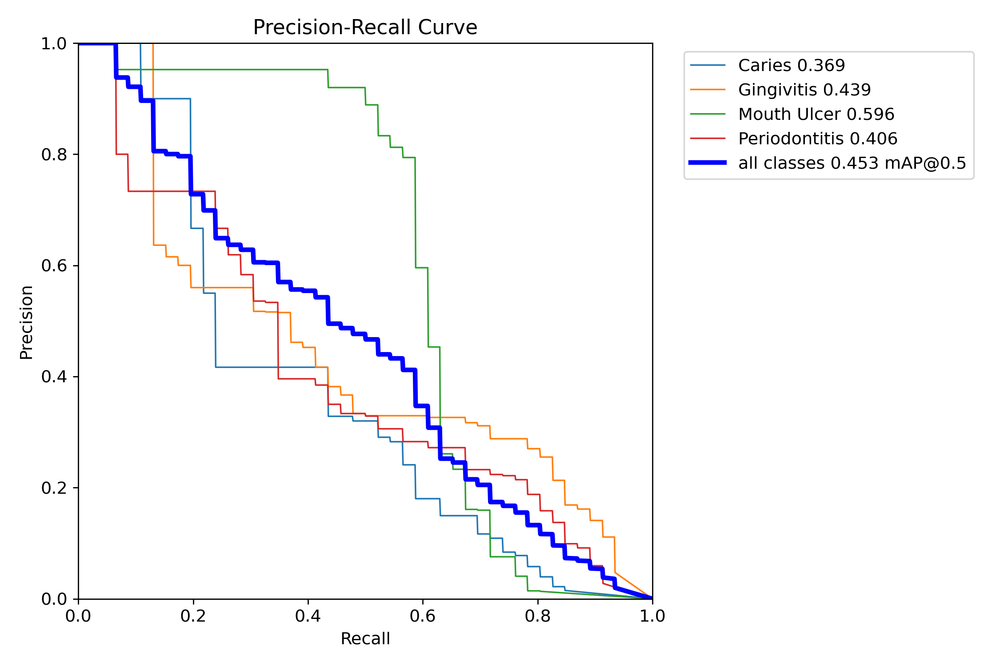

In [ ]:
pr_curve = f"{saved_model_results_path}/train/MaskPR_curve.png"
Image(pr_curve, width=800)

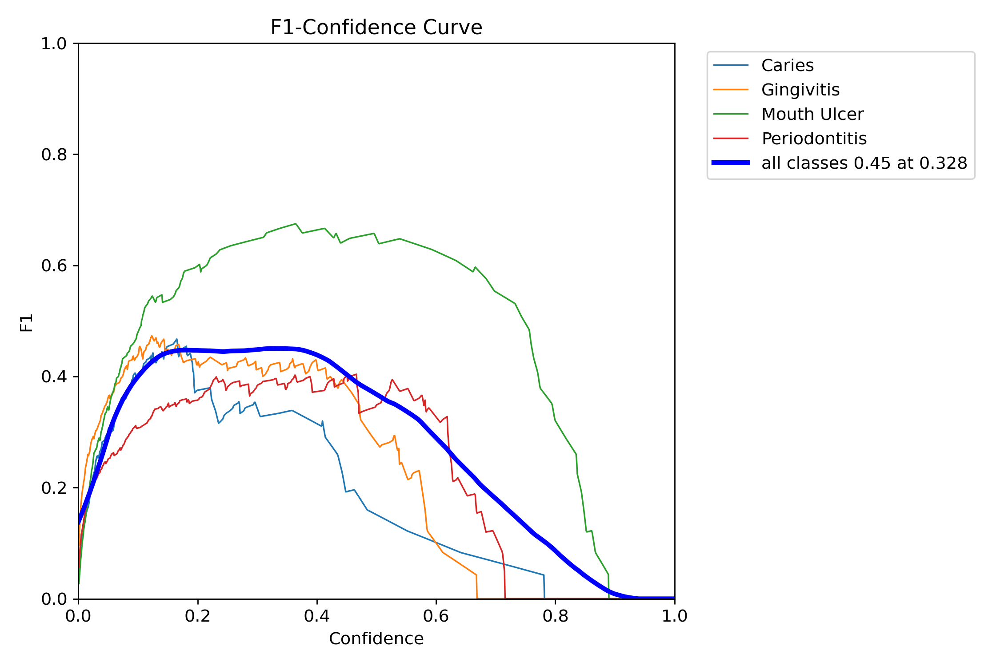

In [ ]:
# bounding box or detection f1 score
f1_curve_box_path = f"{saved_model_results_path}/train/BoxF1_curve.png"
Image(f1_curve_box_path, width=800)

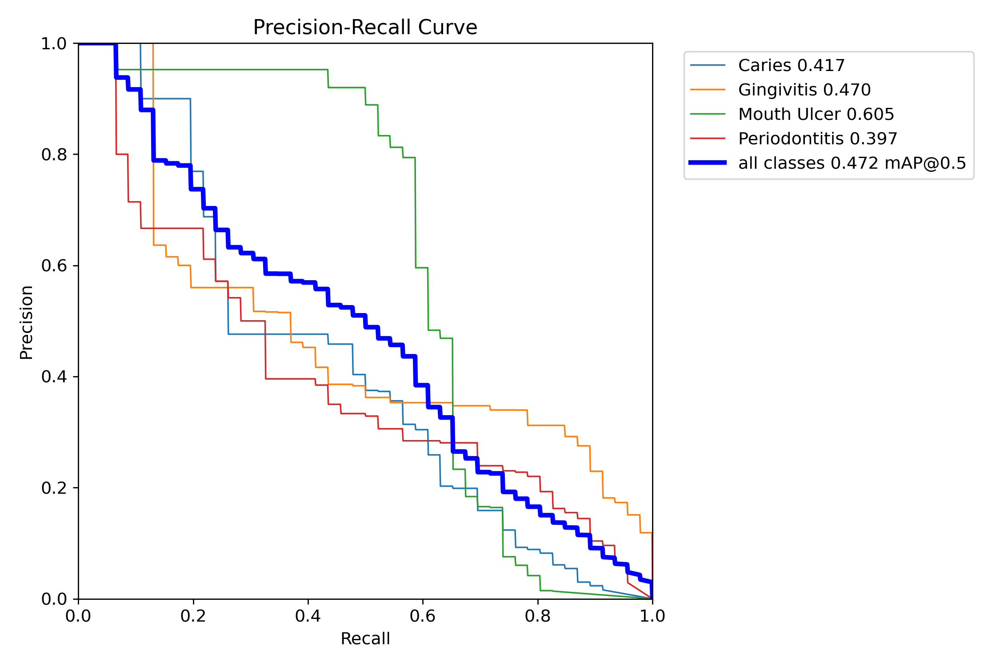

In [ ]:
pr_curve_box_path = f"{saved_model_results_path}/train/BoxPR_curve.png"
Image(pr_curve_box_path, width=800)

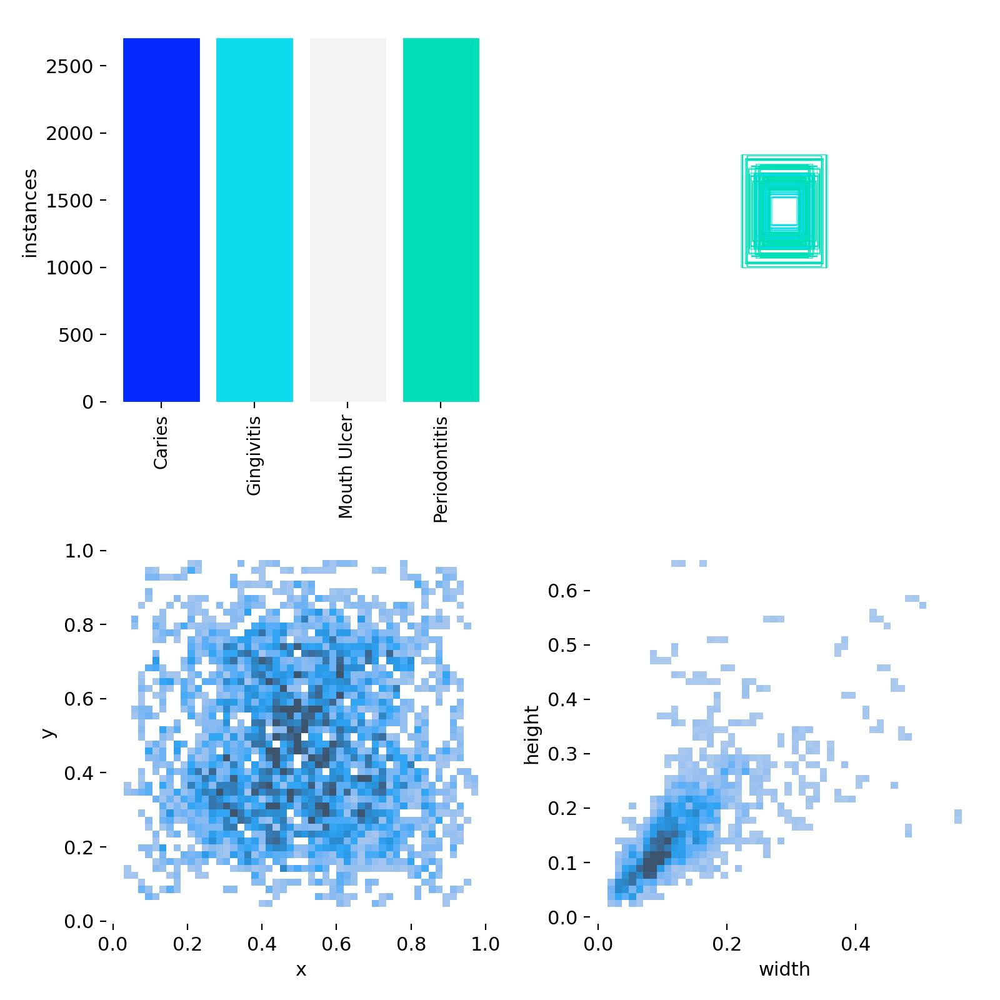

In [ ]:
labels_path = f"{saved_model_results_path}/train/labels.jpg"
Image(labels_path, width=800)

## Validation

In [ ]:
from ultralytics import YOLO

# Load a model
best_weights_path = f"{saved_model_results_path}/train/weights/best.pt"
scaled_up_loaded_best_model = YOLO(best_weights_path)

In [ ]:
scaled_up_loaded_best_model.val()

Ultralytics 8.3.121 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLO11m-seg summary (fused): 138 layers, 22,338,396 parameters, 0 gradients, 123.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1062.7±272.5 MB/s, size: 37.7 KB)


val: Scanning /content/datasets/dental_disease_seg_baln_reaug-4/valid/labels.cache... 77 images, 0 backgrounds, 0 corrupt: 100%|██████████| 77/77 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):   0%|          | 0/5 [00:00<?, ?it/s]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):  20%|██        | 1/5 [00:00<00:03,  1.13it/s]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95):  40%|████      | 2/5 [00:02<00:03,  1.18s/it]

WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100%|██████████| 5/5 [00:06<00:00,  1.23s/it]


                   all         77        184      0.545      0.451      0.472      0.246      0.542      0.429      0.452      0.187
                Caries         22         46      0.704      0.217      0.413       0.15      0.674      0.196      0.364      0.123
            Gingivitis         12         46      0.411      0.435      0.472      0.276      0.412      0.413       0.44      0.166
           Mouth Ulcer         29         46      0.762      0.587      0.605      0.354      0.782      0.587      0.596      0.322
         Periodontitis         19         46      0.303      0.565      0.398      0.205      0.299      0.522      0.407      0.137
Speed: 8.0ms preprocess, 35.0ms inference, 0.1ms loss, 4.5ms postprocess per image
Results saved to runs/segment/val


ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7caebe078c90>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0

In [ ]:
import os
import shutil

source_dir = "/content/datasets/runs/segment/val"  # Path to the folder you want to save
destination_dir = f"/content/drive/MyDrive/ML/DENTAL_THESIS/{model_name}/scaled_up/segment/val"

os.makedirs(destination_dir, exist_ok=True)
shutil.copytree(source_dir, destination_dir, dirs_exist_ok=True)

print(f"All files and folders from {source_dir} have been copied to {destination_dir}.")

All files and folders from /content/datasets/runs/segment/val have been copied to /content/drive/MyDrive/ML/DENTAL_THESIS/yolo11m-seg/scaled_up/segment/val.


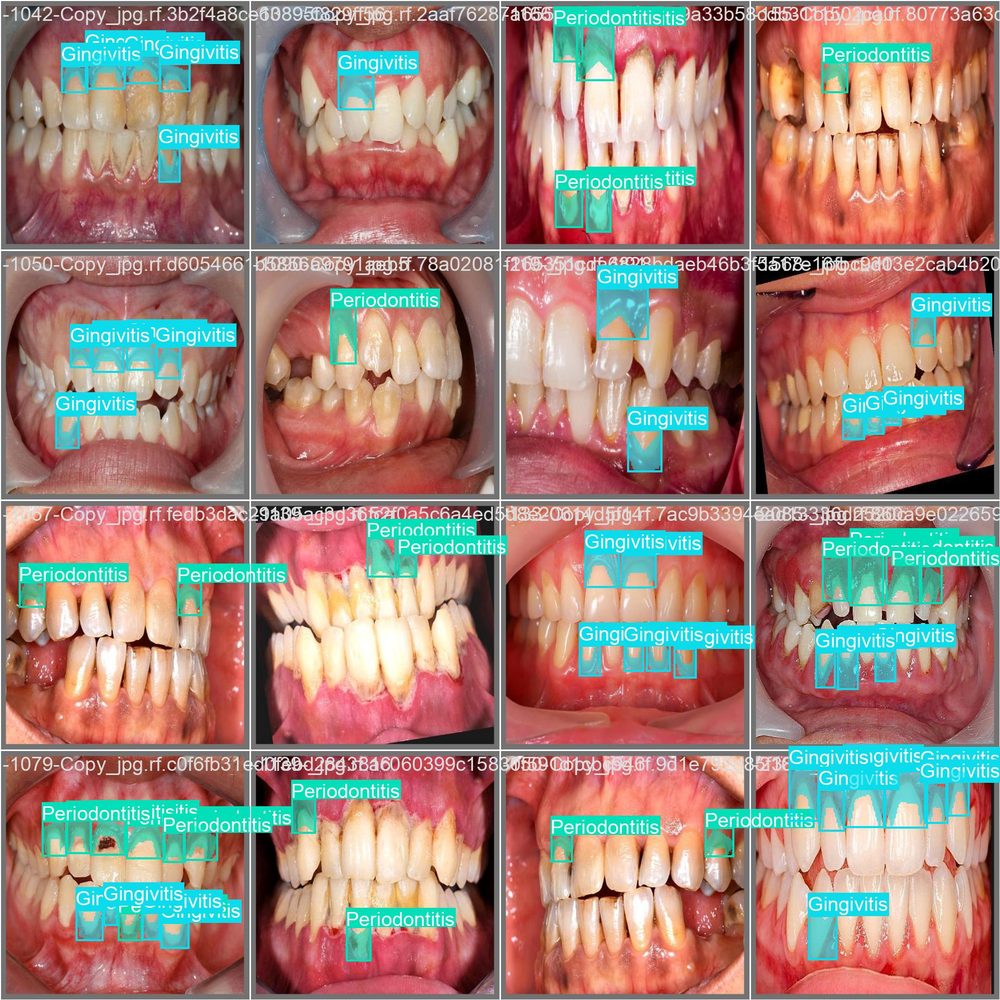

In [ ]:
validation_batch_labels = f"{saved_model_results_path}/val/val_batch0_labels.jpg"
Image(validation_batch_labels, width=1000)

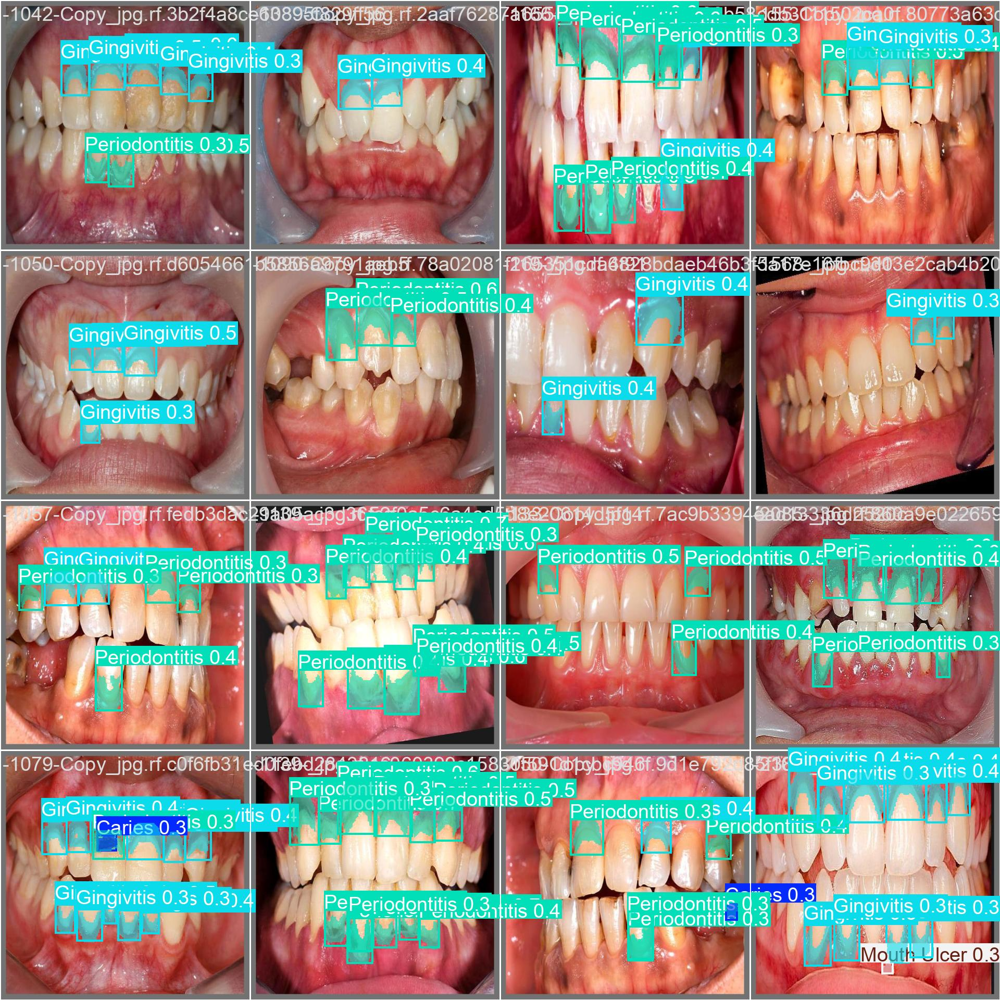

In [ ]:
validation_batch_pred = f"{saved_model_results_path}/val/val_batch0_pred.jpg"
Image(validation_batch_pred, width=1000)

100%|██████████| 48.2k/48.2k [00:00<00:00, 1.77MB/s]


image 1/1 /content/datasets/Gingivitis-vs-Periodontitis.webp: 448x640 1 Gingivitis, 2 Periodontitiss, 106.6ms
Speed: 3.4ms preprocess, 106.6ms inference, 24.6ms postprocess per image at shape (1, 3, 448, 640)
Results saved to runs/segment/predict


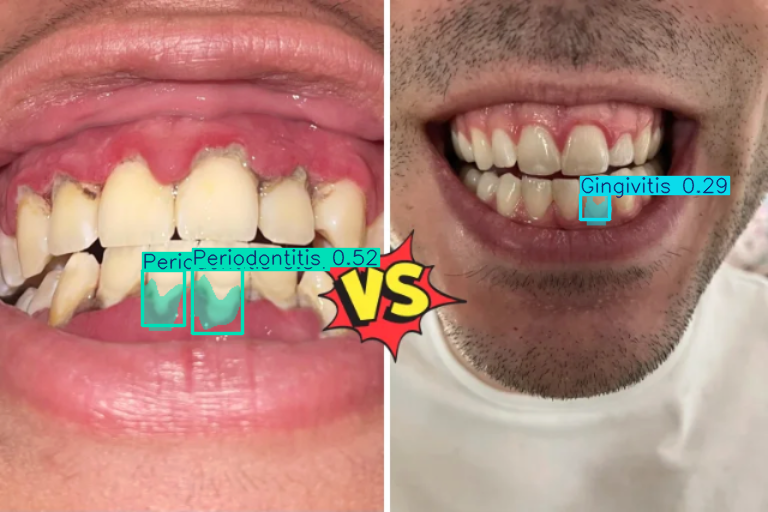

In [ ]:
custom_image_path = "https://www.orisdentalcenter.ae/blog/wp-content/uploads/2024/11/Gingivitis-vs-Periodontitis.webp"
# Perform object detection on an image
results = scaled_up_loaded_best_model(custom_image_path, save=True)
results[0].show()

# CUSTOM ONNX impementation

In [3]:
destination_dir = "/content/drive/MyDrive/ML/DENTAL_THESIS/yolo11m-seg/fine_tuned"
saved_model_results_path = f"{destination_dir}/segment"

## without DYNAMIC and NMS

In [4]:
from ultralytics import YOLO

# Load a model
best_weights_path = f"{saved_model_results_path}/train/weights/best.pt"
ft_loaded_best_model = YOLO(best_weights_path)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [6]:
print(f"{dataset.location}/data.yaml")

/content/datasets/OralCure_Dataset-4/data.yaml


In [8]:
ft_loaded_best_model.export(
    format="onnx",
    nms=True,
    data=f"{dataset.location}/data.yaml",
)

Ultralytics 8.3.134 🚀 Python-3.11.12 torch-2.6.0+cu124 CPU (Intel Xeon 2.20GHz)
YOLO11m-seg summary (fused): 138 layers, 22,338,396 parameters, 0 gradients, 123.0 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/ML/DENTAL_THESIS/yolo11m-seg/fine_tuned/segment/train/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) ((1, 300, 38), (1, 32, 160, 160)) (43.1 MB)

ONNX: starting export with onnx 1.17.0 opset 19...
ONNX: slimming with onnxslim 0.1.53...
ONNX: export success ✅ 9.4s, saved as '/content/drive/MyDrive/ML/DENTAL_THESIS/yolo11m-seg/fine_tuned/segment/train/weights/best.onnx' (85.6 MB)

Export complete (15.4s)
Results saved to /content/drive/MyDrive/ML/DENTAL_THESIS/yolo11m-seg/fine_tuned/segment/train/weights
Predict:         yolo predict task=segment model=/content/drive/MyDrive/ML/DENTAL_THESIS/yolo11m-seg/fine_tuned/segment/train/weights/best.onnx imgsz=640  
Validate:        yolo val task=segment model=/content/drive/MyDrive/ML/DENTAL_THESIS/yolo

'/content/drive/MyDrive/ML/DENTAL_THESIS/yolo11m-seg/fine_tuned/segment/train/weights/best.onnx'

In [9]:
!yolo val task=segment model=/content/drive/MyDrive/ML/DENTAL_THESIS/yolo11m-seg/fine_tuned/segment/train/weights/best.onnx imgsz=640 data=/content/datasets/OralCure_Dataset-4/data.yaml

Ultralytics 8.3.134 🚀 Python-3.11.12 torch-2.6.0+cu124 CPU (Intel Xeon 2.20GHz)
Loading /content/drive/MyDrive/ML/DENTAL_THESIS/yolo11m-seg/fine_tuned/segment/train/weights/best.onnx for ONNX Runtime inference...
Using ONNX Runtime CPUExecutionProvider
Setting batch=1 input of shape (1, 3, 640, 640)
100% 755k/755k [00:00<00:00, 19.9MB/s]
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1349.3±457.3 MB/s, size: 36.3 KB)
val: Scanning /content/datasets/OralCure_Dataset-4/valid/labels... 77 images, 0 backgrounds, 0 corrupt: 100% 77/77 [00:00<00:00, 947.89it/s]
val: New cache created: /content/datasets/OralCure_Dataset-4/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% 77/77 [02:26<00:00,  1.91s/it]
                   all         77        184      0.577      0.549      0.529      0.307      0.555      0.548      0.512      0.258
                Caries         22         46      0.

## Usage

In [10]:
from ultralytics import YOLO

best_weights_path = f"{saved_model_results_path}/train/weights/best.onnx"
onnx_loaded_best_model = YOLO(best_weights_path)

In [12]:
import supervision as sv
import onnxruntime
import cv2
import numpy as np

In [13]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

class YOLOv11nms:
    def __init__(self, path, conf_thres=0.4, num_masks=32):
        """
        Args:
            path (str): Path to the exported ONNX model.
            conf_thres (float): Confidence threshold for filtering detections.
            num_masks (int): Number of mask coefficients (should match export, e.g., 32).
        """
        self.conf_threshold = conf_thres
        self.num_masks = num_masks
        self.initialize_model(path)

    def initialize_model(self, path):
        # Create ONNX Runtime session with GPU (if available) or CPU.
        self.session = onnxruntime.InferenceSession(
            path, providers=['CUDAExecutionProvider', 'CPUExecutionProvider']
        )
        self.get_input_details()
        self.get_output_details()

    def get_input_details(self):
        model_inputs = self.session.get_inputs()
        self.input_names = [inp.name for inp in model_inputs]
        self.input_shape = model_inputs[0].shape  # Expected shape: (1, 3, 640, 640)
        self.input_height = self.input_shape[2]
        self.input_width = self.input_shape[3]

    def get_output_details(self):
        model_outputs = self.session.get_outputs()
        self.output_names = [out.name for out in model_outputs]

    def prepare_input(self, image):
        # Record the original image dimensions.
        self.img_height, self.img_width = image.shape[:2]
        # Convert BGR (OpenCV format) to RGB.
        img = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        # Resize to the model’s input size (e.g., 640x640).
        img = cv2.resize(img, (self.input_width, self.input_height))
        # Normalize pixel values to [0, 1].
        img = img.astype(np.float32) / 255.0
        # Convert from HWC to CHW format.
        img = img.transpose(2, 0, 1)
        # Add batch dimension: shape becomes (1, 3, 640, 640).
        input_tensor = np.expand_dims(img, axis=0)
        return input_tensor

    def inference(self, input_tensor):
        outputs = self.session.run(self.output_names, {self.input_names[0]: input_tensor})
        return outputs

    def segment_objects(self, image):
        """
        Processes an image and returns:
          - boxes: Bounding boxes (rescaled to original image coordinates).
          - scores: Confidence scores.
          - class_ids: Detected class indices.
          - masks: Binary segmentation masks (aligned with the original image).
        """
        # Preprocess the image.
        input_tensor = self.prepare_input(image)
        outputs = self.inference(input_tensor)

        # Process detection output.
        # Detection output shape is (1, 300, 38) (post-NMS & transposed).
        detections = np.squeeze(outputs[0], axis=0)  # Now shape: (300, 38)

        # Filter out detections below the confidence threshold.
        valid_mask = detections[:, 4] > self.conf_threshold
        detections = detections[valid_mask]

        if detections.shape[0] == 0:
            return np.array([]), np.array([]), np.array([]), np.array([])

        # Extract detection results.
        # boxes_model: boxes in model input coordinates (e.g., in a 640x640 space)
        boxes_model = detections[:, :4]  # Format: (x1, y1, x2, y2)
        scores = detections[:, 4]
        class_ids = detections[:, 5].astype(np.int64)
        mask_coeffs = detections[:, 6:]  # 32 mask coefficients

        # Rescale boxes for final drawing on the original image.
        boxes_draw = self.rescale_boxes(
            boxes_model,
            (self.input_height, self.input_width),
            (self.img_height, self.img_width)
        )

        # Process the mask output using the boxes in model coordinates.
        masks = self.process_mask_output(mask_coeffs, outputs[1], boxes_model)

        return boxes_draw, scores, class_ids, masks

    def process_mask_output(self, mask_coeffs, mask_feature_map, boxes_model):
        """
        Generates segmentation masks for each detection.

        Args:
            mask_coeffs (np.ndarray): (N, 32) mask coefficients for N detections.
            mask_feature_map (np.ndarray): Output mask feature map with shape (1, 32, 160, 160).
            boxes_model (np.ndarray): Bounding boxes in model input coordinates.

        Returns:
            mask_maps (np.ndarray): Binary masks for each detection, with shape
                                    (N, original_img_height, original_img_width).
        """
        # Squeeze the mask feature map: (1, 32, 160, 160) -> (32, 160, 160)
        mask_feature_map = np.squeeze(mask_feature_map, axis=0)
        # Reshape to (32, 25600) where 25600 = 160 x 160.
        mask_feature_map_reshaped = mask_feature_map.reshape(self.num_masks, -1)
        # Combine mask coefficients with the mask feature map.
        # Resulting shape: (N, 25600) → then reshape to (N, 160, 160)
        masks = sigmoid(np.dot(mask_coeffs, mask_feature_map_reshaped))
        masks = masks.reshape(-1, mask_feature_map.shape[1], mask_feature_map.shape[2])

        # Get mask feature map dimensions.
        mask_h, mask_w = mask_feature_map.shape[1], mask_feature_map.shape[2]
        # Rescale boxes from model coordinates (e.g., 640x640) to mask feature map coordinates (e.g., 160x160).
        scale_boxes = self.rescale_boxes(
            boxes_model,
            (self.input_height, self.input_width),
            (mask_h, mask_w)
        )
        # Also, compute boxes in original image coordinates for placing the mask.
        boxes_draw = self.rescale_boxes(
            boxes_model,
            (self.input_height, self.input_width),
            (self.img_height, self.img_width)
        )

        # Create an empty array for final masks with the same size as the original image.
        mask_maps = np.zeros((boxes_model.shape[0], self.img_height, self.img_width), dtype=np.uint8)

        # Determine blur size based on the ratio between the original image and the mask feature map.
        blur_size = (
            max(1, int(self.img_width / mask_w)),
            max(1, int(self.img_height / mask_h))
        )

        for i in range(boxes_model.shape[0]):
            # Get the detection box in mask feature map coordinates.
            sx1, sy1, sx2, sy2 = scale_boxes[i]
            sx1, sy1, sx2, sy2 = int(np.floor(sx1)), int(np.floor(sy1)), int(np.ceil(sx2)), int(np.ceil(sy2))

            # Get the corresponding box in the original image.
            ox1, oy1, ox2, oy2 = boxes_draw[i]
            ox1, oy1, ox2, oy2 = int(np.floor(ox1)), int(np.floor(oy1)), int(np.ceil(ox2)), int(np.ceil(oy2))

            # Crop the predicted mask region from the raw mask.
            cropped_mask = masks[i][sy1:sy2, sx1:sx2]
            if cropped_mask.size == 0 or (ox2 - ox1) <= 0 or (oy2 - oy1) <= 0:
                continue
            # Resize the cropped mask to the size of the detection box in the original image.
            resized_mask = cv2.resize(cropped_mask, (ox2 - ox1, oy2 - oy1), interpolation=cv2.INTER_CUBIC)
            # Apply a slight blur to smooth the mask edges.
            resized_mask = cv2.blur(resized_mask, blur_size)
            # Threshold the mask to obtain a binary mask.
            bin_mask = (resized_mask > 0.5).astype(np.uint8)
            # Place the binary mask into the correct location on the full mask.
            mask_maps[i, oy1:oy2, ox1:ox2] = bin_mask

        return mask_maps

    @staticmethod
    def rescale_boxes(boxes, input_shape, target_shape):
        """
        Rescales boxes from one coordinate space to another.

        Args:
            boxes (np.ndarray): Array of boxes (N, 4) with format [x1, y1, x2, y2].
            input_shape (tuple): (height, width) of the current coordinate space.
            target_shape (tuple): (height, width) of the target coordinate space.

        Returns:
            np.ndarray: Scaled boxes of shape (N, 4).
        """
        in_h, in_w = input_shape
        tgt_h, tgt_w = target_shape
        scale = np.array([tgt_w / in_w, tgt_h / in_h, tgt_w / in_w, tgt_h / in_h])
        return boxes * scale

    def __call__(self, image):
        # This allows you to call the instance directly, e.g.:
        # boxes, scores, class_ids, masks = detector(image)
        return self.segment_objects(image)

In [14]:
# Load the model and create InferenceSession
best_weights_path = f"{saved_model_results_path}/train/weights/best.onnx"

detector = YOLOv11nms(best_weights_path, conf_thres=0.5)

In [28]:
def predict(imgpath):
    img = cv2.imread(imgpath)

    # Detect Objects (returns bounding boxes, scores, class_ids, and segmentation masks)
    boxes, scores, class_ids, masks = detector(img)
    classes = ["Caries", "Gingivitis", "Mouth Ulcer", "Periodontitis"]
    # Create labels in the format: 'label-XX%' where XX is the score in percent.
    labels = [f"{classes[class_id]}-{int(score * 100)}%" for score, class_id in zip(scores, class_ids)]

    boolean_mask = masks.astype(bool)

    box_annotator = sv.BoxAnnotator()
    label_annotator = sv.LabelAnnotator()
    mask_annotator = sv.MaskAnnotator()

    detections = sv.Detections(
        xyxy=boxes,
        confidence=scores,
        class_id=class_ids,
        mask=boolean_mask
    )

    annotate = box_annotator.annotate(scene=img.copy(), detections=detections)
    annotate = label_annotator.annotate(scene=annotate, detections=detections, labels=labels)
    annotate = mask_annotator.annotate(scene=annotate, detections=detections)

    sv.plot_image(annotate)

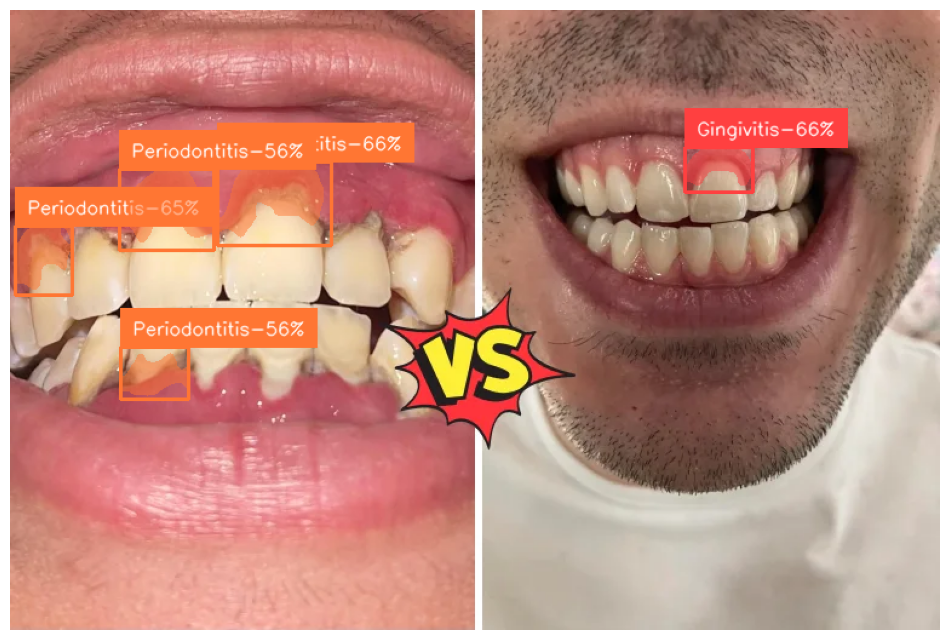

In [29]:
predict("/content/Gingivitis-vs-Periodontitis.webp")

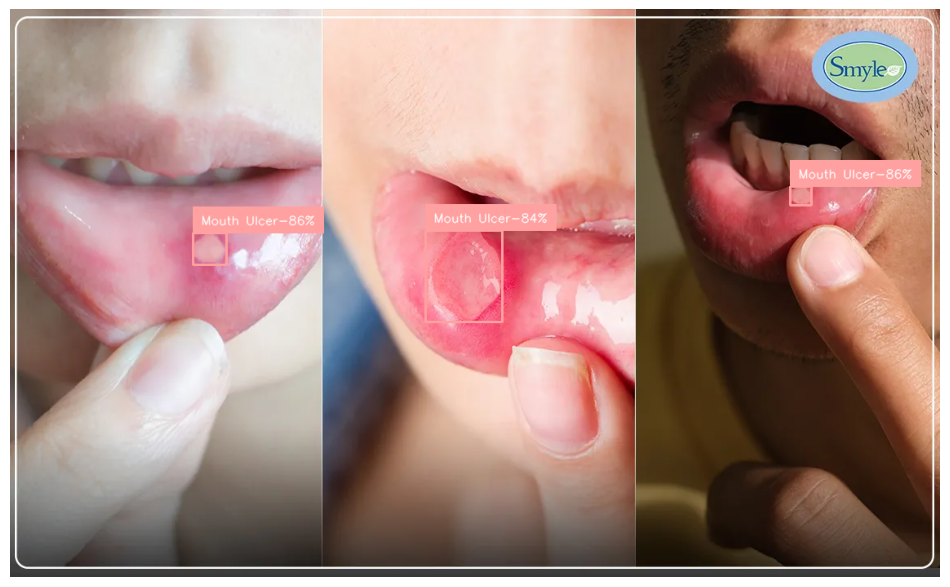

In [31]:
predict("/content/types-of-mouth-ulcers.png")

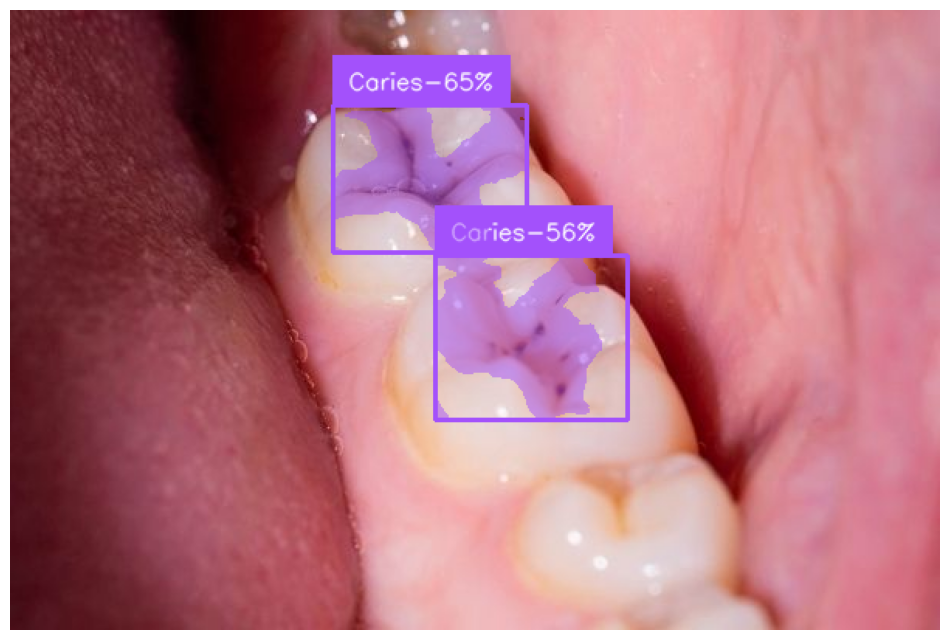

In [32]:
predict("/content/tratamiento-de-la-caries-dental.jpg")